# Athlete Injury Prediction - Minor Thesis MATH1332

Prepared by: Mariangela Chandler

Covers data checks, feature selection, LSTM, CNN and RNN modelling, model evaluation, and explainable machine learning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
# Load prepared data and set prediction periods
HISTORY_DAYS = 14
FORECAST_DAYS = 7
df = pd.read_csv(
    "athlete_day_final.csv",
    na_values=["NA", "N/A", "na", ""])
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (366000, 97)


,athlete_id,date,resting_hr,hrv,sleep_hours,deep_sleep,light_sleep,rem_sleep,sleep_quality,body_battery_morning,...,weekly_training_hours,recovery_rate,lifestyle,sleep_time_norm,sleep_quality_athlete,nutrition_factor,stress_factor,smoking_factor,drinking_factor,activity_present
0,006e66d8-101c-41f0-b541-44ee43f81058,2024-01-01,51.912317,90.872687,7.659744,1.096015,4.913882,1.649846,0.802,60.0,...,11.1,1.21,Balanced Competitor,7.937176,0.839725,0.818278,0.230409,0.0,0.121456,0
1,006e66d8-101c-41f0-b541-44ee43f81058,2024-01-02,50.246351,104.226122,7.961573,1.245846,4.936415,1.779312,0.841,97.0,...,11.1,1.21,Balanced Competitor,7.937176,0.839725,0.818278,0.230409,0.0,0.121456,1
2,006e66d8-101c-41f0-b541-44ee43f81058,2024-01-03,50.834952,102.297988,8.206464,1.280846,5.092240,1.833378,0.921,100.0,...,11.1,1.21,Balanced Competitor,7.937176,0.839725,0.818278,0.230409,0.0,0.121456,1
3,006e66d8-101c-41f0-b541-44ee43f81058,2024-01-04,51.825352,93.148501,7.452858,1.141325,4.660177,1.651356,0.841,82.0,...,11.1,1.21,Balanced Competitor,7.937176,0.839725,0.818278,0.230409,0.0,0.121456,1
4,006e66d8-101c-41f0-b541-44ee43f81058,2024-01-05,51.691678,100.121628,9.510787,1.372977,6.081197,2.056613,0.802,73.0,...,11.1,1.21,Balanced Competitor,7.937176,0.839725,0.818278,0.230409,0.0,0.121456,1


## Data Checks

In [3]:
# Check dates, identifiers and daily records
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print("Dataset shape:", df.shape)
print("Number of athletes:", df["athlete_id"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Missing athlete IDs:", df["athlete_id"].isna().sum())
print("Missing or invalid dates:", df["date"].isna().sum())
duplicate_count = df.duplicated(subset=["athlete_id", "date"]).sum()
print("Duplicate athlete-date records:", duplicate_count)
rows_per_athlete = df.groupby("athlete_id").size()
print("Fewest rows per athlete:", rows_per_athlete.min())
print("Most rows per athlete:", rows_per_athlete.max())

Dataset shape: (366000, 97)
Number of athletes: 1000
Date range: 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Missing athlete IDs: 0
Missing or invalid dates: 0
Duplicate athlete-date records: 0
Fewest rows per athlete: 366
Most rows per athlete: 366


In [4]:
# Sort records and check injury labels
df = df.sort_values(["athlete_id", "date"]).reset_index(drop=True)
print("Injury label counts:")
print(df["injury"].value_counts(dropna=False))
invalid_labels = df["injury"].notna() & ~df["injury"].isin([0, 1])
print("Missing injury labels:", df["injury"].isna().sum())
print("Invalid injury labels:", invalid_labels.sum())

# Check injury patterns within each athlete
previous_injury = df.groupby("athlete_id")["injury"].shift(1)
injury_patterns = pd.Series({
    "Recorded injured days": df["injury"].eq(1).sum(),
    "Changes from 0 to 1": (previous_injury.eq(0) & df["injury"].eq(1)).sum(),
    "Consecutive injured days": (previous_injury.eq(1) & df["injury"].eq(1)).sum()
})
print("Injury patterns:")
print(injury_patterns)

Injury label counts:
injury
0    336198
1     29802
Name: count, dtype: int64
Missing injury labels: 0
Invalid injury labels: 0
Injury patterns:
Recorded injured days       29802
Changes from 0 to 1          4476
Consecutive injured days    25325
dtype: int64


## Missing Values

In [5]:
# Summarise missing values
missing_summary = pd.DataFrame({
    "Missing_count": df.isna().sum(),
    "Missing_percent": df.isna().mean() * 100,
    "Data_type": df.dtypes.astype(str)
})
missing_summary = missing_summary[
    missing_summary["Missing_count"] > 0
].sort_values("Missing_percent", ascending=False)
print("Columns with missing values:", len(missing_summary))
print(missing_summary.round(2).to_string())

Columns with missing values: 49
                                             Missing_count  Missing_percent Data_type
avg_pace_min_100m                                   270896            74.02   float64
training_effect_anaerobic                           261362            71.41   float64
avg_pace_min_km                                     261362            71.41   float64
intensity_variability                               195167            53.32   float64
power_z1                                            195167            53.32   float64
power_z2                                            195167            53.32   float64
power_z3                                            195167            53.32   float64
power_z6                                            195167            53.32   float64
normalized_power                                    195167            53.32   float64
avg_power                                           195167            53.32   float64
power_z4              

In [6]:
# Compare missingness by activity status
print("Activity status counts:")
print(df["activity_present"].value_counts(dropna=False))
no_activity = df["activity_present"].eq(0)
has_activity = df["activity_present"].eq(1)
missing_columns = missing_summary.index
missing_by_activity = pd.DataFrame({
    "Missing_no_activity_%": df.loc[no_activity, missing_columns].isna().mean() * 100,
    "Missing_with_activity_%": df.loc[has_activity, missing_columns].isna().mean() * 100
})
print("Missingness by activity status:")
print(missing_by_activity.round(2).to_string())

Activity status counts:
activity_present
1    275527
0     90473
Name: count, dtype: int64
Missingness by activity status:
                                             Missing_no_activity_%  Missing_with_activity_%
avg_pace_min_100m                                            100.0                    65.48
training_effect_anaerobic                                    100.0                    62.02
avg_pace_min_km                                              100.0                    62.02
intensity_variability                                        100.0                    38.00
power_z1                                                     100.0                    38.00
power_z2                                                     100.0                    38.00
power_z3                                                     100.0                    38.00
power_z6                                                     100.0                    38.00
normalized_power                                 

In [7]:
# Check missingness by sport
sport_columns = ["sport_bike", "sport_run", "sport_swim", "sport_strength"]
features_to_check = missing_by_activity.index[
    missing_by_activity["Missing_with_activity_%"] > 0
]
missing_by_sport = {}
for sport in sport_columns:
    mask = has_activity & df[sport].gt(0)
    missing_by_sport[sport] = df.loc[mask, features_to_check].isna().mean() * 100
print(pd.DataFrame(missing_by_sport).round(2).to_string())

                           sport_bike  sport_run  sport_swim  sport_strength
avg_pace_min_100m               76.95      79.13        0.00           77.43
training_effect_anaerobic       74.81       0.00       77.04           75.43
avg_pace_min_km                 74.81       0.00       77.04           75.43
intensity_variability            0.00      58.87       58.60           50.83
power_z1                         0.00      58.87       58.60           50.83
power_z2                         0.00      58.87       58.60           50.83
power_z3                         0.00      58.87       58.60           50.83
power_z6                         0.00      58.87       58.60           50.83
normalized_power                 0.00      58.87       58.60           50.83
avg_power                        0.00      58.87       58.60           50.83
power_z4                         0.00      58.87       58.60           50.83
power_z5                         0.00      58.87       58.60           50.83

In [8]:
# Check sport-specific measurements
bike_day = df["sport_bike"].gt(0)
run_day = df["sport_run"].gt(0)
swim_day = df["sport_swim"].gt(0)
bike_features = [
    "avg_power", "normalized_power", "intensity_variability",
    "power_z1", "power_z2", "power_z3", "power_z4", "power_z5", "power_z6"
]
candidate_rules = {
    "avg_pace_min_100m": swim_day,
    "avg_pace_min_km": run_day,
    "training_effect_anaerobic": run_day,
    "training_effect_aerobic": run_day | swim_day,
    "avg_speed_kph": bike_day | run_day | swim_day
}
candidate_rules.update({feature: bike_day for feature in bike_features})
checks = []
for feature, applicable in candidate_rules.items():
    checks.append({
        "Feature": feature,
        "Missing_when_expected": (applicable & df[feature].isna()).sum(),
        "Present_outside_expected": (has_activity & ~applicable & df[feature].notna()).sum()
    })
print(pd.DataFrame(checks).set_index("Feature").to_string())

                           Missing_when_expected  Present_outside_expected
Feature                                                                   
avg_pace_min_100m                              0                         0
avg_pace_min_km                                0                         0
training_effect_anaerobic                      0                         0
training_effect_aerobic                        0                         0
avg_speed_kph                                  0                         0
avg_power                                      0                         0
normalized_power                               0                         0
intensity_variability                          0                         0
power_z1                                       0                         0
power_z2                                       0                         0
power_z3                                       0                         0
power_z4                 

In [9]:
# Preserve missingness before filling values
numeric_columns = df.select_dtypes(include=np.number).columns
numeric_missing_columns = [
    column for column in numeric_columns if df[column].isna().any()
]
original_missing = df[numeric_missing_columns].isna().copy()
print("Numeric columns with missing values:", len(numeric_missing_columns))

Numeric columns with missing values: 49


In [10]:
# Inspect available activity measurements
activity_rows = df["activity_present"].eq(1)
imputation_summary = df.loc[
    activity_rows, numeric_missing_columns
].agg(["count", "mean", "median", "min", "max"]).T
print(imputation_summary.round(3).to_string())

                                                count     mean   median      min      max
intensity_factor                             275527.0    0.706    0.670    0.400    1.000
intensity_variability                        170833.0    1.013    1.010    1.000    1.090
avg_hr                                       275527.0  154.274  155.500  103.000  202.000
max_hr_activity                              275527.0  174.905  178.000  111.000  218.000
avg_speed_kph                                272877.0   19.388   18.571    3.001   46.500
avg_power                                    170833.0  153.832  148.000   57.000  454.000
normalized_power                             170833.0  156.037  150.000   57.000  479.000
avg_pace_min_km                              104638.0    5.349    5.090    2.700    8.500
avg_pace_min_100m                             95104.0    1.547    1.527    1.242    2.000
training_effect_aerobic                      177906.0    1.133    1.000    0.100    5.000
training_e

In [11]:
# Fill counts on days without activity
count_columns = [
    c for c in df.columns if c.startswith(("sport_", "workout_"))
]
count_columns += ["number_of_activities"]
for column in count_columns:
    mask = no_activity & df[column].isna()
    df.loc[mask, column] = 0

In [12]:
# Encode no-activity measurements
activity_columns = [
    "duration_minutes", "tss", "distance_km", "distance_m",
    "work_kilojoules", "elevation_gain", "intensity_factor",
    "intensity_variability", "avg_hr", "max_hr_activity",
    "avg_speed_kph", "avg_power", "normalized_power",
    "avg_pace_min_km", "avg_pace_min_100m",
    "training_effect_aerobic", "training_effect_anaerobic"
]
activity_columns += [f"hr_z{i}" for i in range(1, 7)]
activity_columns += [f"power_z{i}" for i in range(1, 7)]
for column in activity_columns:
    mask = no_activity & df[column].isna()
    df.loc[mask, column] = 0

In [13]:
# Encode non-applicable measurements
for feature, applicable in candidate_rules.items():
    mask = ~applicable & df[feature].isna()
    df.loc[mask, feature] = 0

# Preserve original availability
availability_columns = []
for column in numeric_missing_columns:
    indicator = f"{column}__available"
    df[indicator] = (~original_missing[column]).astype("float32")
    availability_columns.append(indicator)

remaining_missing = df.isna().sum()
print("Remaining missing values:")
print(remaining_missing[remaining_missing > 0].to_string())

Remaining missing values:
Series([], )


In [14]:
# Define injury in the following seven days
future_injury = pd.concat([
    df.groupby("athlete_id")["injury"].shift(-day).rename(f"day_ahead_{day}")
    for day in range(1, FORECAST_DAYS + 1)
], axis=1)
complete_future = future_injury.notna().all(axis=1)
df["injury_next_7d"] = (
    future_injury.max(axis=1).where(complete_future).astype("Int64")
)
print("Seven-day outcome counts:")
print(df["injury_next_7d"].value_counts(dropna=False))

Seven-day outcome counts:
injury_next_7d
0       303523
1        55477
<NA>      7000
Name: count, dtype: Int64


In [15]:
# Require full history, follow-up and no current injury
day_number = df.groupby("athlete_id").cumcount() + 1
has_history = day_number >= HISTORY_DAYS
has_future = df["injury_next_7d"].notna()
currently_uninjured = df["injury"].eq(0)
df["eligible_prediction"] = has_history & has_future & currently_uninjured
eligible = df.loc[df["eligible_prediction"]]
print("Eligible prediction days:", len(eligible))
print("Outcome counts:")
print(eligible["injury_next_7d"].value_counts().sort_index())
print("Positive outcome (%):", round(eligible["injury_next_7d"].mean() * 100, 2))

Eligible prediction days: 316999
Outcome counts:
injury_next_7d
0    286714
1     30285
Name: count, dtype: Int64
Positive outcome (%): 9.55


## Feature Selection

In [16]:
# Exclude outcomes and identifiers
excluded_columns = [
    "athlete_id", "date", "injury", "injury_next_7d",
    "eligible_prediction", "split"
]
candidate_features = [c for c in df.columns if c not in excluded_columns]
numeric_features = df[candidate_features].select_dtypes(include=np.number).columns.tolist()
category_columns = ["gender", "lifestyle"]
X_daily = df[numeric_features].copy()
print("Numeric inputs:", len(numeric_features))
print("Structured fields excluded: hrv_range, hr_zones")

Numeric inputs: 139
Structured fields excluded: hrv_range, hr_zones


In [17]:
# Encode categories from the full dataset
X_daily = df[numeric_features].copy()
encoded_categories = {}
for column in category_columns:
    categories = sorted(df[column].dropna().unique())
    for category in categories:
        encoded_categories[f"{column}__{category}"] = df[column].eq(category).astype("float32")
    encoded_categories[f"{column}__unknown"] = (~df[column].isin(categories)).astype("float32")
X_daily = pd.concat([X_daily, pd.DataFrame(encoded_categories, index=df.index)], axis=1)
X_daily = X_daily.astype("float32")
assert X_daily.columns.is_unique
assert np.isfinite(X_daily.to_numpy()).all()
print("Daily input table:", X_daily.shape)

Daily input table: (366000, 149)


In [18]:
# Average each eligible 14-day history
selection_endpoints = df.index[df["eligible_prediction"]]
history_summaries = {}
for feature in X_daily.columns:
    averages = X_daily[feature].groupby(
        df["athlete_id"], sort=False
    ).rolling(HISTORY_DAYS, min_periods=HISTORY_DAYS).mean()
    averages = averages.reset_index(level=0, drop=True)
    history_summaries[feature] = averages.reindex(selection_endpoints)
X_selection = pd.DataFrame(history_summaries).astype("float32")
y_selection = df.loc[selection_endpoints, "injury_next_7d"].astype("int32")
assert X_selection.index.equals(y_selection.index)
assert np.isfinite(X_selection.to_numpy()).all()
print("Full-dataset summaries:", X_selection.shape)
print("Outcome counts:")
print(y_selection.value_counts())

Full-dataset summaries: (316999, 149)
Outcome counts:
injury_next_7d
0    286714
1     30285
Name: count, dtype: int64


## Correlation

In [19]:
# Calculate correlations and identify strong pairs
corr_threshold = 0.90
corr_matrix = X_selection.corr()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = upper.stack().reset_index()
high_corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]
high_corr_pairs["Abs_Correlation"] = high_corr_pairs["Correlation"].abs()
high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Abs_Correlation"] >= corr_threshold
].sort_values("Abs_Correlation", ascending=False)
print("Highly correlated pairs:", len(high_corr_pairs))
display(high_corr_pairs)

Highly correlated pairs: 875


,Feature_1,Feature_2,Correlation,Abs_Correlation
7653,age,hrv_baseline,-1.000000,1.000000
9798,sport_swim__available,workout_Unplanned.Extra.Workout..Endurance.__a...,1.000000,1.000000
9833,sport_strength__available,workout_Core.Strength__available,1.000000,1.000000
9811,sport_swim__available,hr_z4__available,1.000000,1.000000
9812,sport_swim__available,hr_z5__available,1.000000,1.000000
...,...,...,...,...
2605,intensity_factor,max_hr_activity,0.915354,0.915354
2677,intensity_factor,avg_speed_kph__available,0.904711,0.904711
3475,avg_pace_min_km,sport_run,0.901644,0.901644
3541,avg_pace_min_km,avg_pace_min_km__available,0.901644,0.901644


In [20]:
# Group features connected by strong correlations
connections = {}
for first, second in high_corr_pairs[["Feature_1", "Feature_2"]].itertuples(index=False, name=None):
    connections.setdefault(first, set()).add(second)
    connections.setdefault(second, set()).add(first)
visited, groups = set(), []
for feature in connections:
    if feature in visited:
        continue
    pending, group = [feature], []
    while pending:
        current = pending.pop()
        if current in visited:
            continue
        visited.add(current)
        group.append(current)
        pending.extend(connections[current] - visited)
    groups.append(sorted(group))
correlation_groups = pd.DataFrame([
    {"Group": i + 1, "Feature_count": len(group), "Features": ", ".join(group)}
    for i, group in enumerate(sorted(groups, key=len, reverse=True))
])
print("Connected feature groups:", len(correlation_groups))
display(correlation_groups)

Connected feature groups: 14


,Group,Feature_count,Features
0,1,40,"activity_present, avg_hr, avg_hr__available, a..."
1,2,11,"avg_power__available, intensity_variability, i..."
2,3,6,"deep_sleep, light_sleep, rem_sleep, sleep_hour..."
3,4,5,"avg_pace_min_km, avg_pace_min_km__available, s..."
4,5,4,"avg_pace_min_100m, avg_pace_min_100m__availabl..."
5,6,3,"age, hrv, hrv_baseline"
6,7,2,"actual_tss, tss"
7,8,2,"gender__female, gender__male"
8,9,2,"avg_power, normalized_power"
9,10,2,"resting_hr, resting_hr_athlete"


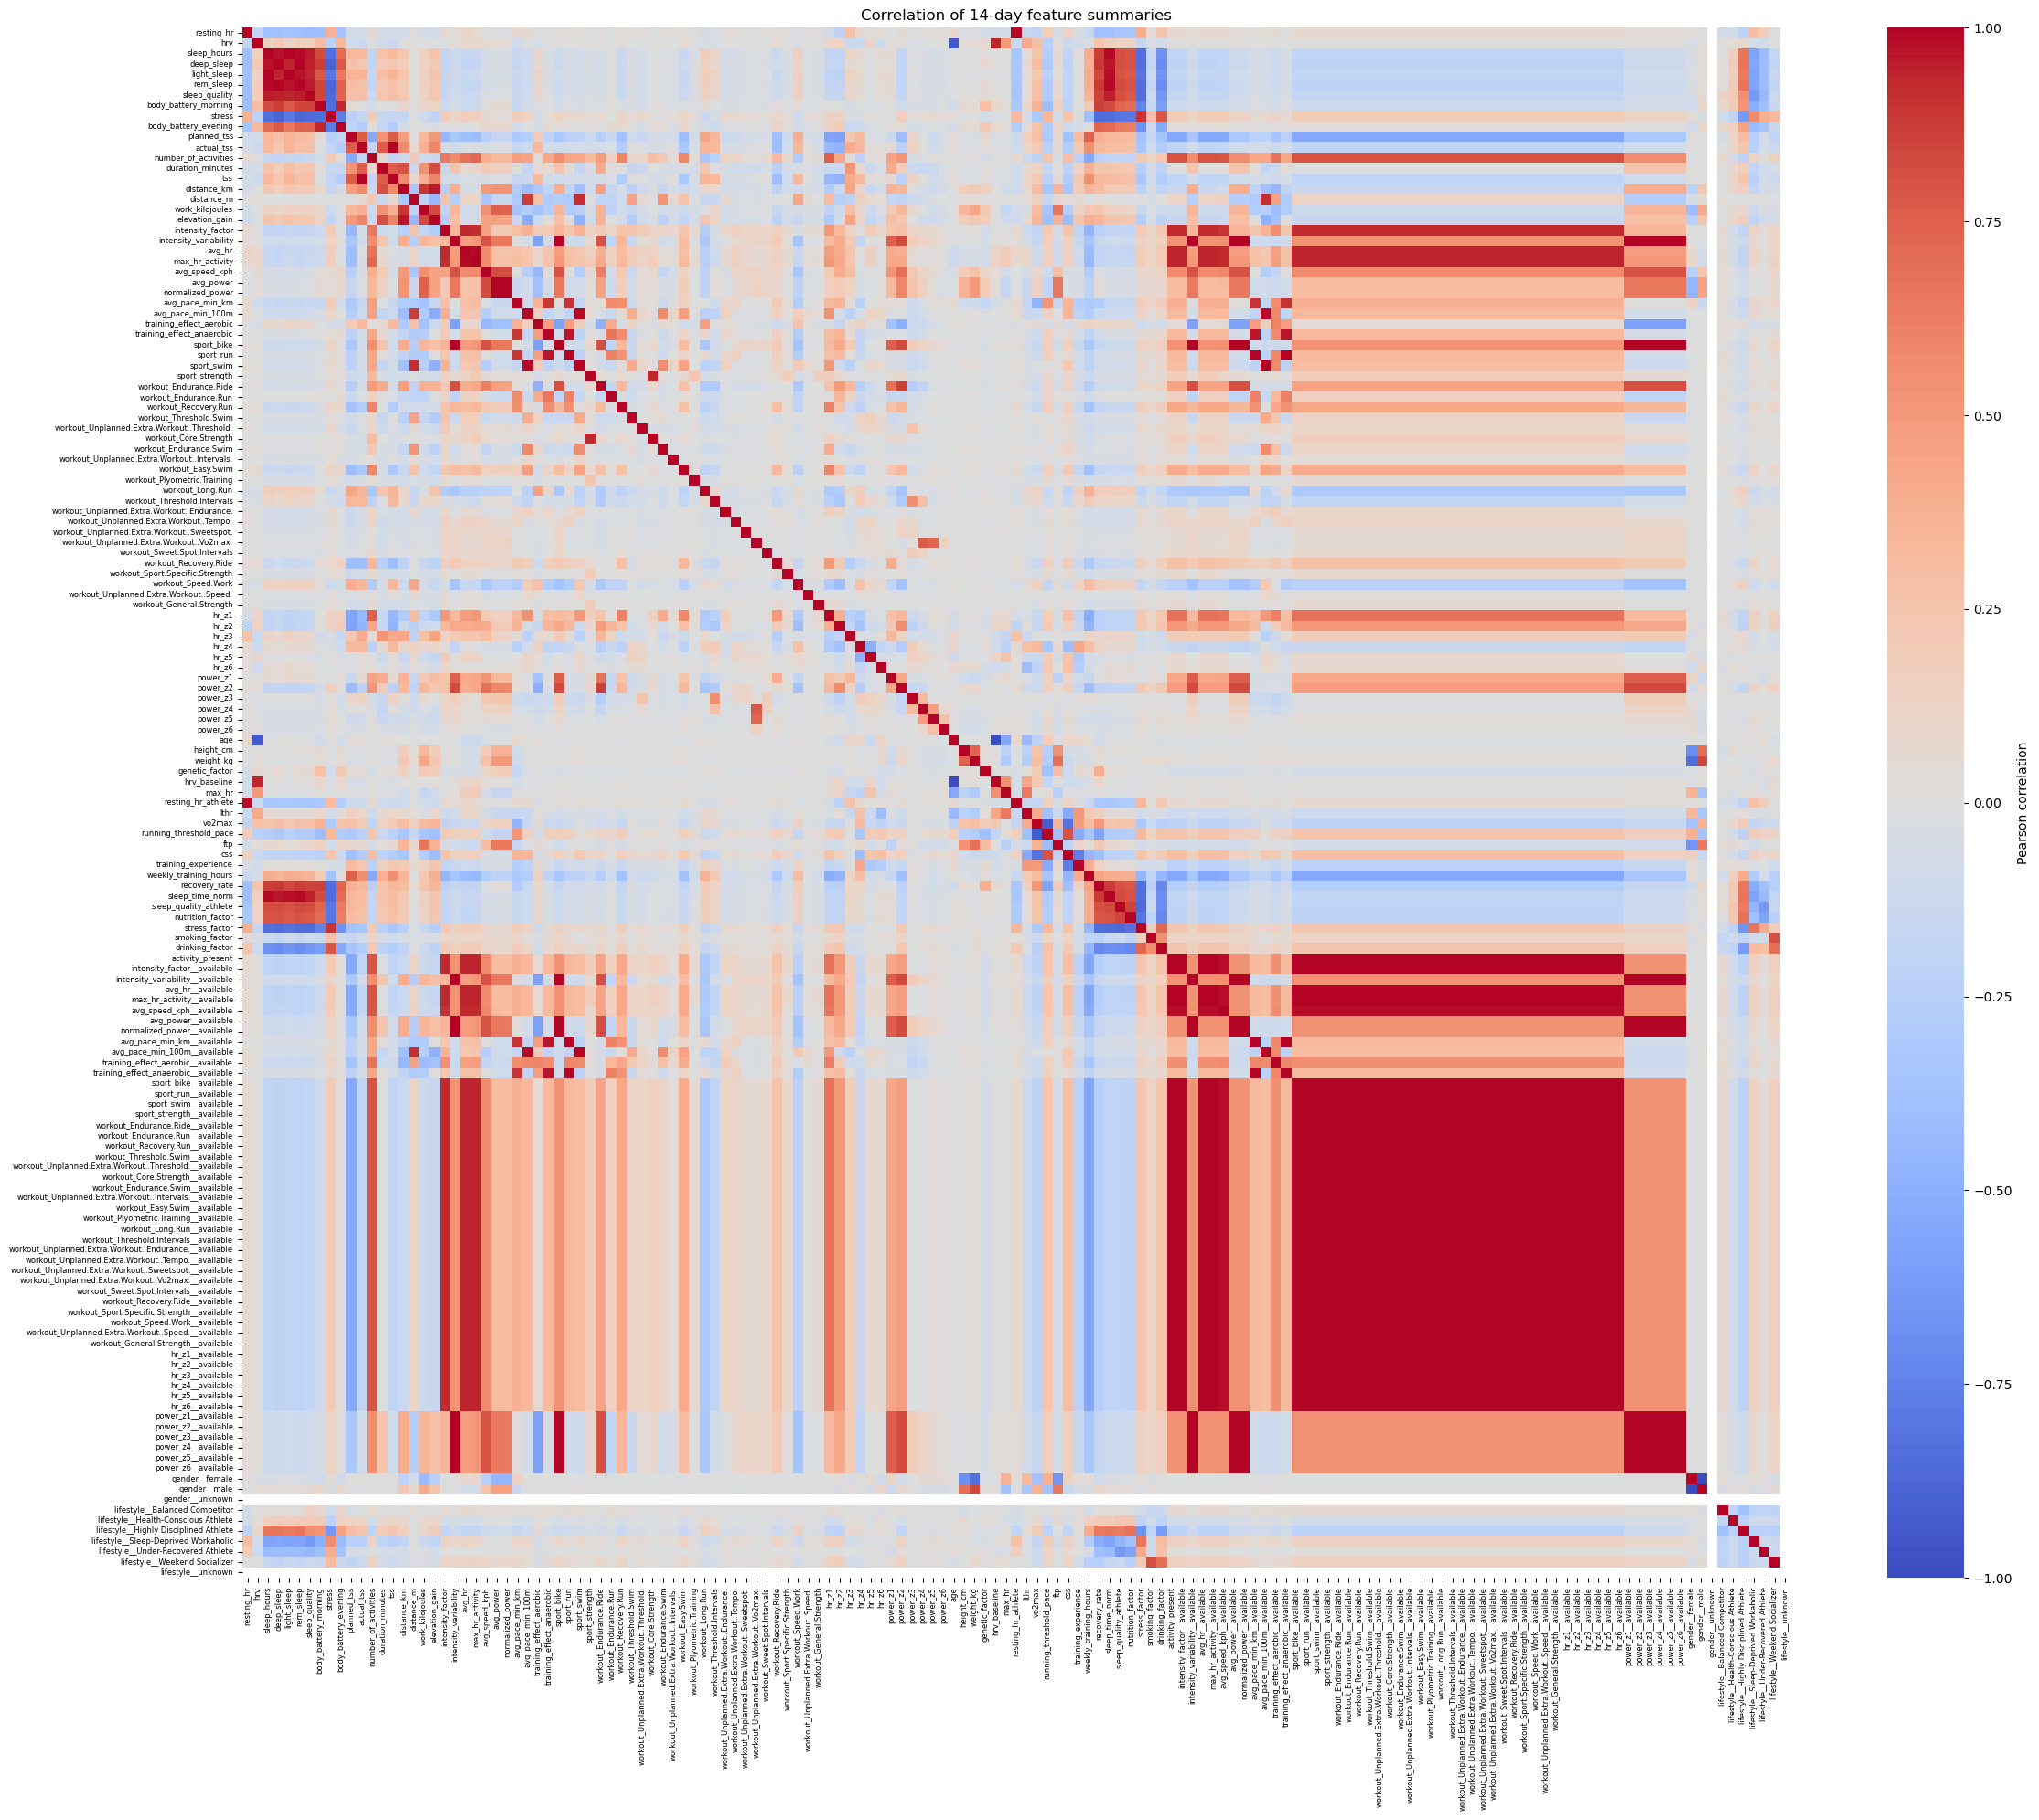

In [21]:
# Plot all candidate inputs
import seaborn as sns
correlation_fig, ax = plt.subplots(figsize=(24, 20))
sns.heatmap(
    corr_matrix, ax=ax, cmap="coolwarm", center=0,
    vmin=-1, vmax=1, xticklabels=True, yticklabels=True,
    cbar_kws={"label": "Pearson correlation"}
)
ax.set_title("Correlation of 14-day feature summaries")
ax.tick_params(axis="both", labelsize=6)
correlation_fig.tight_layout()
plt.show()

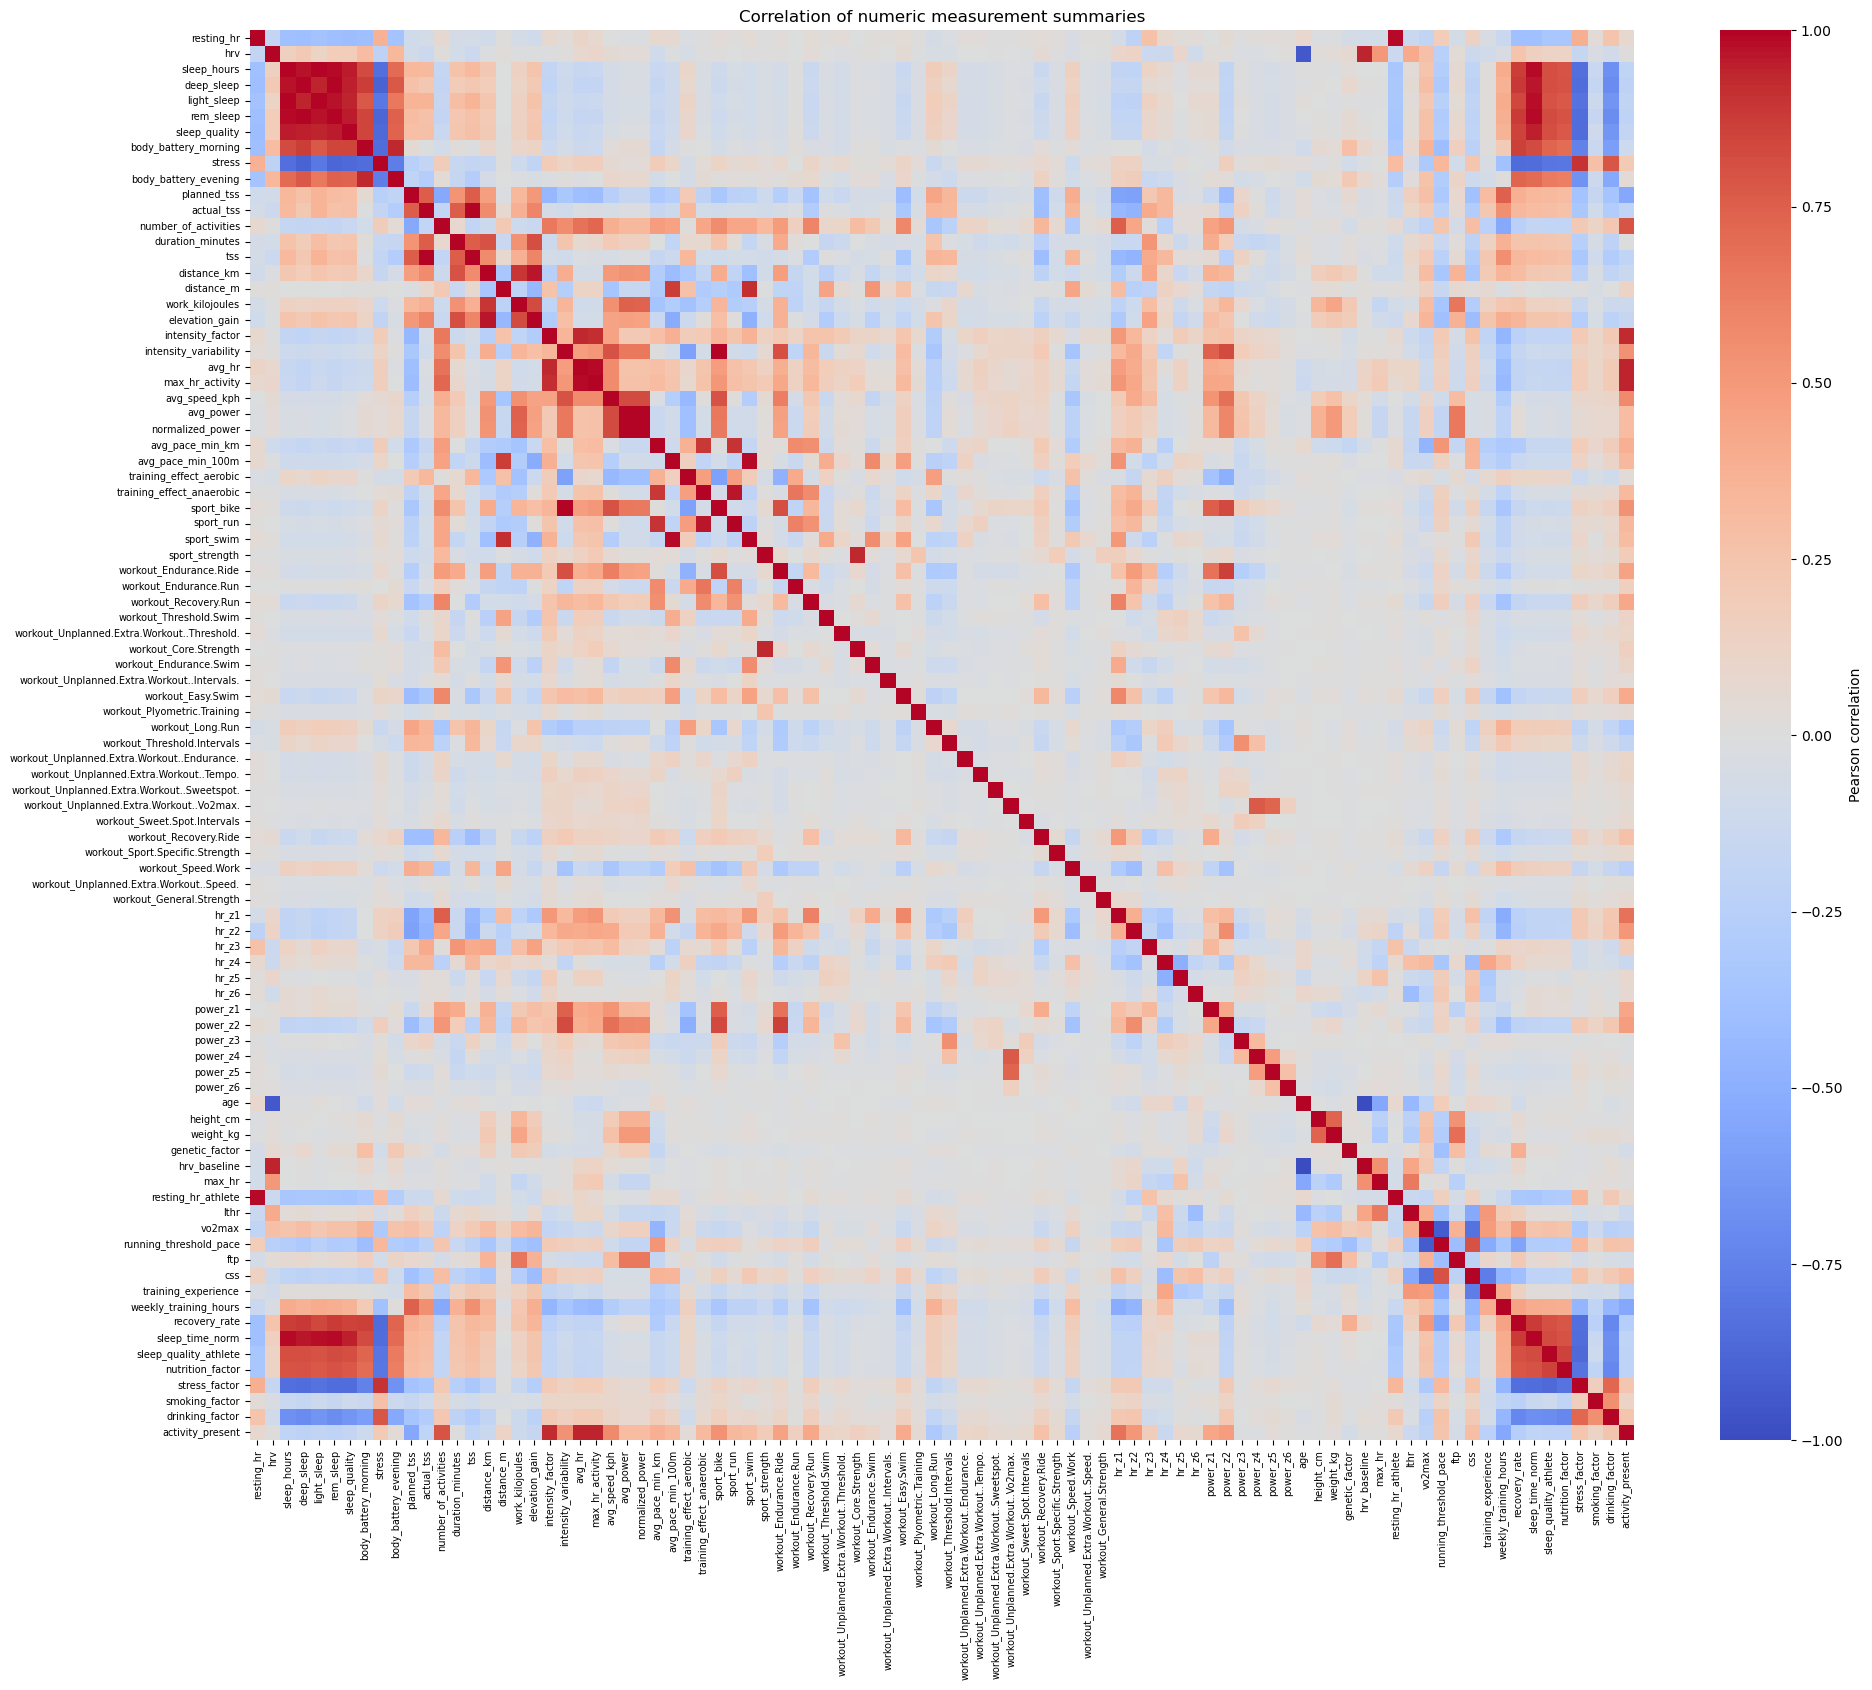

In [22]:
# Plot measurements without availability indicators
measurement_features = [
    c for c in corr_matrix.columns
    if not c.endswith("__available") and "__" not in c
]
measurement_corr = corr_matrix.loc[measurement_features, measurement_features]
measurement_fig, ax = plt.subplots(figsize=(20, 17))
sns.heatmap(
    measurement_corr, ax=ax, cmap="coolwarm", center=0,
    vmin=-1, vmax=1, xticklabels=True, yticklabels=True,
    cbar_kws={"label": "Pearson correlation"}
)
ax.set_title("Correlation of numeric measurement summaries")
ax.tick_params(axis="both", labelsize=7)
measurement_fig.tight_layout()
plt.show()

**Removing Duplicate Inputs**

In [23]:
# Remove identical summary columns
columns = X_selection.columns.tolist()
values = X_selection.to_numpy()
kept_positions, duplicate_features = [], []
for position, column in enumerate(columns):
    duplicate = any(
        np.array_equal(values[:, position], values[:, previous])
        for previous in kept_positions
    )
    if duplicate:
        duplicate_features.append(column)
    else:
        kept_positions.append(position)
X_selection = X_selection.iloc[:, kept_positions].copy()
print("Duplicate inputs removed:", duplicate_features)

# Use all eligible records for all three methods
assert X_selection.index.equals(y_selection.index)
assert y_selection.nunique() == 2

print("Feature-selection data:", X_selection.shape)
print("Outcome counts:")
print(y_selection.value_counts())

Duplicate inputs removed: ['tss', 'intensity_factor__available', 'intensity_variability__available', 'avg_hr__available', 'max_hr_activity__available', 'avg_power__available', 'normalized_power__available', 'avg_pace_min_km__available', 'avg_pace_min_100m__available', 'training_effect_anaerobic__available', 'sport_bike__available', 'sport_run__available', 'sport_swim__available', 'sport_strength__available', 'workout_Endurance.Ride__available', 'workout_Endurance.Run__available', 'workout_Recovery.Run__available', 'workout_Threshold.Swim__available', 'workout_Unplanned.Extra.Workout..Threshold.__available', 'workout_Core.Strength__available', 'workout_Endurance.Swim__available', 'workout_Unplanned.Extra.Workout..Intervals.__available', 'workout_Easy.Swim__available', 'workout_Plyometric.Training__available', 'workout_Long.Run__available', 'workout_Threshold.Intervals__available', 'workout_Unplanned.Extra.Workout..Endurance.__available', 'workout_Unplanned.Extra.Workout..Tempo.__availab

**Mutual Information**

In [24]:
# Measure association with the injury outcome
from sklearn.feature_selection import mutual_info_classif

discrete_mask = X_selection.nunique().le(2).to_numpy()

mi_scores = mutual_info_classif(
    X_selection,
    y_selection,
    discrete_features=discrete_mask,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": X_selection.columns,
    "MI_Score": mi_scores
}).sort_values(
    "MI_Score", ascending=False
).reset_index(drop=True)

mi_results["MI_Selected"] = mi_results["MI_Score"] > 0

display(mi_results.head(30))

,Feature,MI_Score,MI_Selected
0,distance_m,0.102042,True
1,power_z3,0.086597,True
2,avg_pace_min_100m,0.067870,True
3,power_z4,0.059576,True
4,hr_z4,0.053782,True
5,stress,0.053015,True
6,body_battery_morning,0.050998,True
7,power_z2,0.049666,True
8,hr_z5,0.047920,True
9,power_z1,0.045089,True


**Logistic Regression**

In [25]:
# Select features using L1 regularisation on all eligible records
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
selection_scaler = StandardScaler()
X_lasso_scaled = selection_scaler.fit_transform(X_selection)
lasso_model = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    C=0.1,
    max_iter=500,
    random_state=42
)
lasso_model.fit(X_lasso_scaled, y_selection)
lasso_results = pd.DataFrame({
    "Feature": X_selection.columns,
    "Coefficient": lasso_model.coef_[0]
})
lasso_results["Abs_Coefficient"] = lasso_results["Coefficient"].abs()
lasso_results["LASSO_Selected"] = lasso_results["Abs_Coefficient"] > 1e-8
lasso_results = lasso_results.sort_values(
    "Abs_Coefficient", ascending=False
).reset_index(drop=True)
display(lasso_results.head(30))

,Feature,Coefficient,Abs_Coefficient,LASSO_Selected
0,resting_hr,-4.580430,4.580430,True
1,resting_hr_athlete,4.381962,4.381962,True
2,stress,4.147669,4.147669,True
3,hrv,2.019090,2.019090,True
4,stress_factor,-1.911528,1.911528,True
5,deep_sleep,1.552756,1.552756,True
6,hrv_baseline,-1.124635,1.124635,True
7,light_sleep,-0.964905,0.964905,True
8,drinking_factor,-0.848199,0.848199,True
9,age,0.724806,0.724806,True


**Random Forest**

In [26]:
# Rank features using random forest on all eligible records
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced_subsample"
)
rf_model.fit(X_selection, y_selection)
rf_results = pd.DataFrame({
    "Feature": X_selection.columns,
    "RF_Importance": rf_model.feature_importances_
}).sort_values(
    "RF_Importance", ascending=False
).reset_index(drop=True)
rf_threshold = rf_results["RF_Importance"].mean()
rf_results["RF_Selected"] = (
    rf_results["RF_Importance"] >= rf_threshold
)
display(rf_results.head(30))

,Feature,RF_Importance,RF_Selected
0,stress,0.152840,True
1,hrv,0.034727,True
2,resting_hr,0.032373,True
3,body_battery_evening,0.023792,True
4,deep_sleep,0.021274,True
5,stress_factor,0.019599,True
6,body_battery_morning,0.019162,True
7,sleep_quality,0.018838,True
8,light_sleep,0.017793,True
9,rem_sleep,0.016958,True


**Combining Results of Feature Selection**

In [27]:
# Combine rankings and selection decisions
feature_comparison = mi_results.merge(
    lasso_results, on="Feature", validate="one_to_one"
).merge(rf_results, on="Feature", validate="one_to_one")
selection_columns = ["MI_Selected", "LASSO_Selected", "RF_Selected"]
feature_comparison["Methods_Selected"] = feature_comparison[selection_columns].sum(axis=1)
feature_comparison = feature_comparison.sort_values(
    ["Methods_Selected", "RF_Importance", "MI_Score"],
    ascending=False
).reset_index(drop=True)
display(feature_comparison.head(30))

,Feature,MI_Score,MI_Selected,Coefficient,Abs_Coefficient,LASSO_Selected,RF_Importance,RF_Selected,Methods_Selected
0,stress,0.053015,True,4.147669,4.147669,True,0.152840,True,3
1,hrv,0.004051,True,2.019090,2.019090,True,0.034727,True,3
2,resting_hr,0.005067,True,-4.580430,4.580430,True,0.032373,True,3
3,body_battery_evening,0.025988,True,-0.091568,0.091568,True,0.023792,True,3
4,deep_sleep,0.000703,True,1.552756,1.552756,True,0.021274,True,3
5,stress_factor,0.007674,True,-1.911528,1.911528,True,0.019599,True,3
6,body_battery_morning,0.050998,True,-0.003031,0.003031,True,0.019162,True,3
7,sleep_quality,0.030740,True,0.521222,0.521222,True,0.018838,True,3
8,light_sleep,0.000242,True,-0.964905,0.964905,True,0.017793,True,3
9,planned_tss,0.000400,True,0.053200,0.053200,True,0.015566,True,3


In [28]:
# Count selections by method
selection_summary = pd.DataFrame({
    "Method": ["Mutual information", "L1 logistic regression", "Random forest"],
    "Selected_features": [
        int(mi_results["MI_Selected"].sum()),
        int(lasso_results["LASSO_Selected"].sum()),
        int(rf_results["RF_Selected"].sum())
    ]
})
display(selection_summary)
print("RF importance threshold:", round(rf_threshold, 6))
print("Selection agreement:")
print(feature_comparison["Methods_Selected"].value_counts().sort_index())

,Method,Selected_features
0,Mutual information,97
1,L1 logistic regression,83
2,Random forest,44


RF importance threshold: 0.01
Selection agreement:
Methods_Selected
0     1
1    11
2    51
3    37
Name: count, dtype: int64


In [29]:
# Inspect features selected by multiple methods
consensus_candidates = feature_comparison.loc[
    feature_comparison["Methods_Selected"] >= 2
].copy()
print("Selected by at least two methods:", len(consensus_candidates))
display(consensus_candidates)

Selected by at least two methods: 88


,Feature,MI_Score,MI_Selected,Coefficient,Abs_Coefficient,LASSO_Selected,RF_Importance,RF_Selected,Methods_Selected
0,stress,0.053015,True,4.147669,4.147669,True,0.152840,True,3
1,hrv,0.004051,True,2.019090,2.019090,True,0.034727,True,3
2,resting_hr,0.005067,True,-4.580430,4.580430,True,0.032373,True,3
3,body_battery_evening,0.025988,True,-0.091568,0.091568,True,0.023792,True,3
4,deep_sleep,0.000703,True,1.552756,1.552756,True,0.021274,True,3
...,...,...,...,...,...,...,...,...,...
83,lifestyle__Sleep-Deprived Workaholic,0.000002,True,0.011049,0.011049,True,0.000801,False,2
84,workout_Sport.Specific.Strength,0.000430,True,0.038676,0.038676,True,0.000660,False,2
85,lifestyle__Under-Recovered Athlete,0.000028,True,-0.000853,0.000853,True,0.000541,False,2
86,workout_General.Strength,0.000447,True,0.008678,0.008678,True,0.000503,False,2


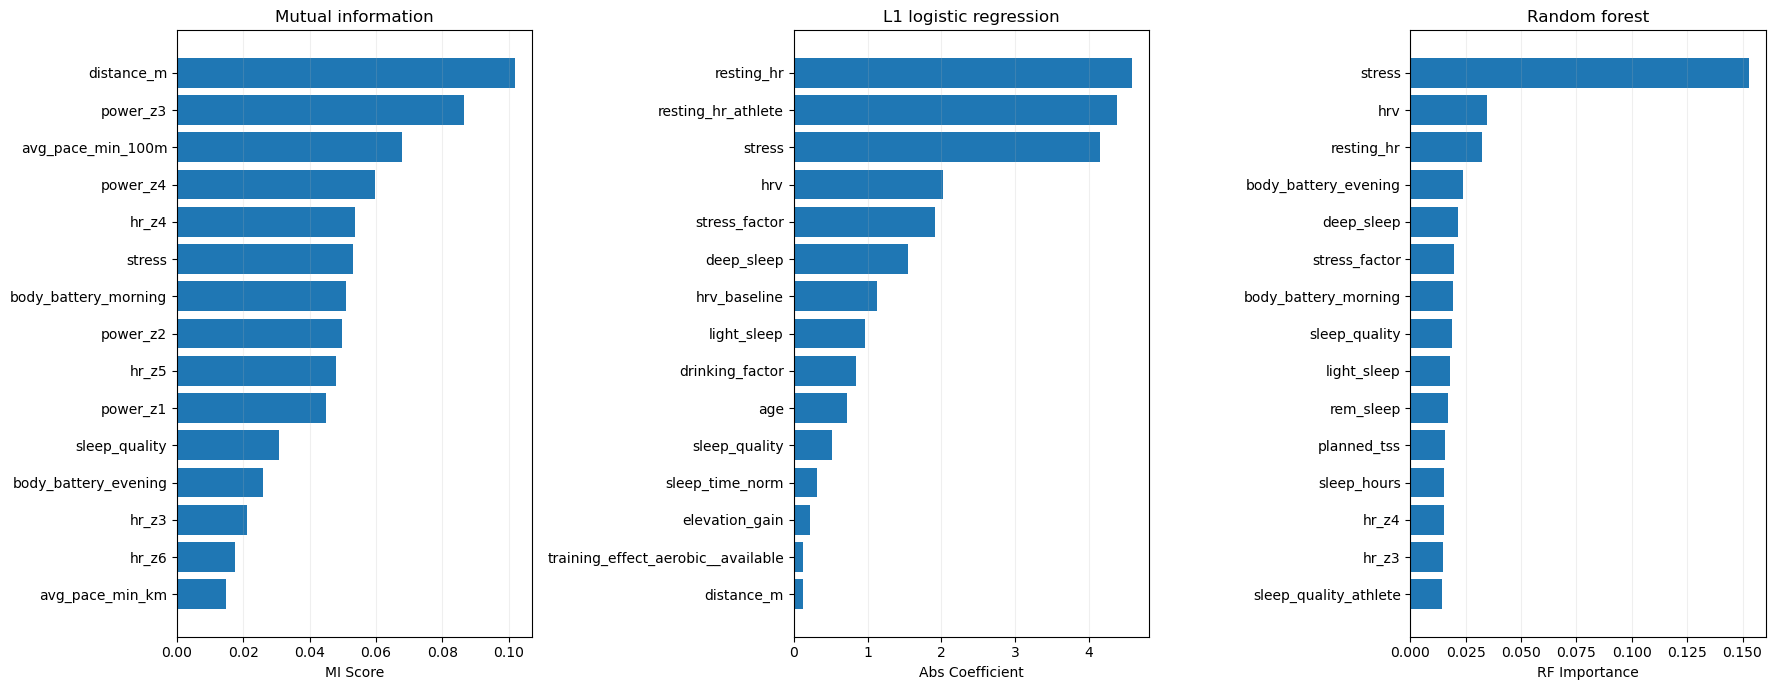

In [30]:
# Plot the top 15 features per method
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
plot_settings = [
    (mi_results, "MI_Score", "Mutual information"),
    (lasso_results, "Abs_Coefficient", "L1 logistic regression"),
    (rf_results, "RF_Importance", "Random forest")
]
for ax, (table, score, title) in zip(axes, plot_settings):
    top = table.head(15).iloc[::-1]
    ax.barh(top["Feature"], top[score])
    ax.set_title(title)
    ax.set_xlabel(score.replace("_", " "))
    ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

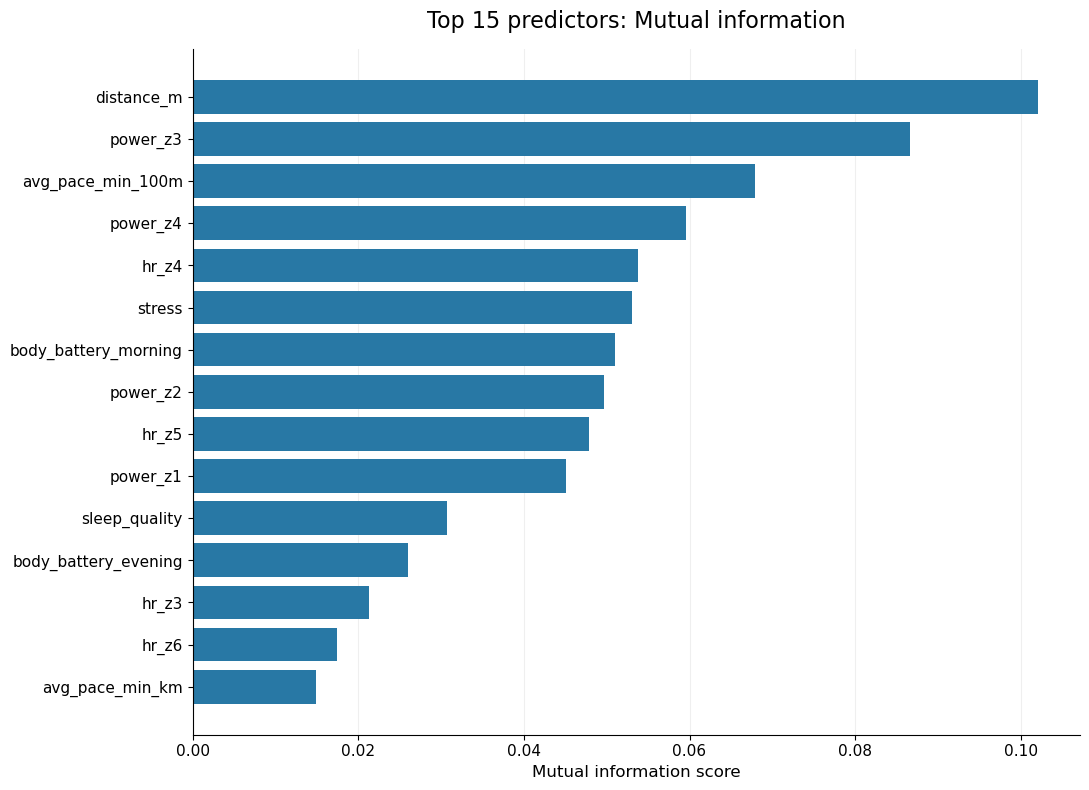

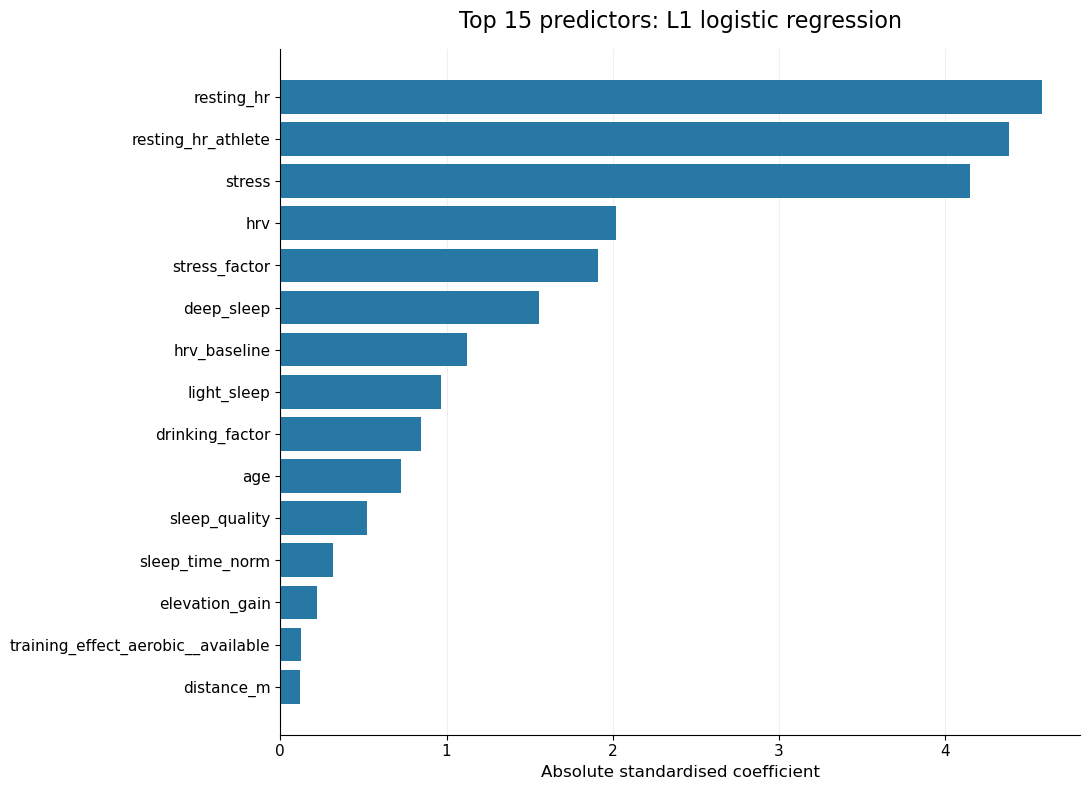

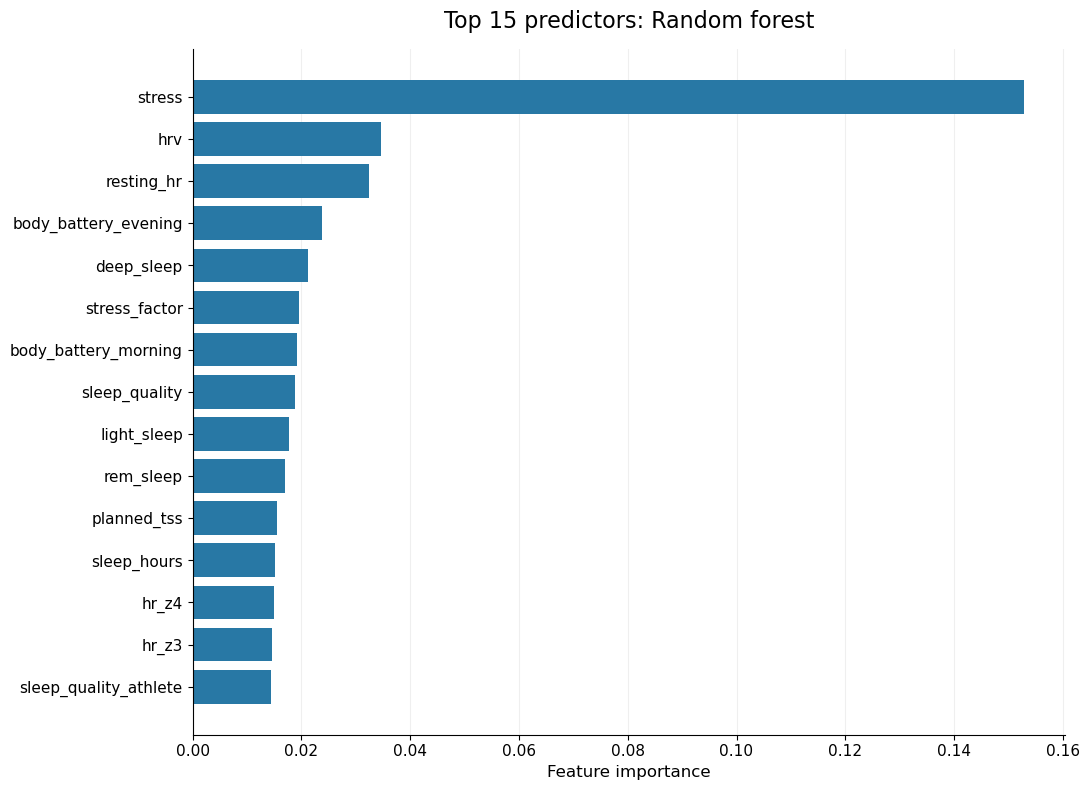

Files saved in: C:\Users\santo\OneDrive\Documents\repos\MATH1332-Minor-Thesis-Semester-2-2026\output\feature_selection_graphs


In [31]:
from pathlib import Path
import matplotlib.pyplot as plt

# Folder for saved graphs
output_folder = Path("output") / "feature_selection_graphs"
output_folder.mkdir(parents=True, exist_ok=True)

plot_settings = [
    (
        mi_results,
        "MI_Score",
        "Mutual information",
        "Mutual information score",
        "mutual_information"
    ),
    (
        lasso_results,
        "Abs_Coefficient",
        "L1 logistic regression",
        "Absolute standardised coefficient",
        "l1_logistic_regression"
    ),
    (
        rf_results,
        "RF_Importance",
        "Random forest",
        "Feature importance",
        "random_forest"
    )
]

for table, score, title, xlabel, filename in plot_settings:

    # Select and order the top 15 features
    top = (
        table.sort_values(score, ascending=False)
        .head(15)
        .iloc[::-1]
    )

    # Create a separate figure for each method
    fig, ax = plt.subplots(figsize=(11, 8))

    ax.barh(top["Feature"], top[score], color="#2878A5")

    ax.set_title(
        f"Top 15 predictors: {title}",
        fontsize=16,
        pad=15
    )
    ax.set_xlabel(xlabel, fontsize=12)
    ax.tick_params(axis="both", labelsize=11)

    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    # Save before displaying
    fig.savefig(
        output_folder / f"{filename}.png",
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        output_folder / f"{filename}.svg",
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

print(f"Files saved in: {output_folder.resolve()}")

In [32]:
# Inspect agreement across all three methods
all_three_candidates = feature_comparison.loc[
    feature_comparison["Methods_Selected"] == 3
].copy()
print("Selected by all three methods:", len(all_three_candidates))
display(all_three_candidates)

Selected by all three methods: 37


,Feature,MI_Score,MI_Selected,Coefficient,Abs_Coefficient,LASSO_Selected,RF_Importance,RF_Selected,Methods_Selected
0,stress,0.053015,True,4.147669,4.147669,True,0.152840,True,3
1,hrv,0.004051,True,2.019090,2.019090,True,0.034727,True,3
2,resting_hr,0.005067,True,-4.580430,4.580430,True,0.032373,True,3
3,body_battery_evening,0.025988,True,-0.091568,0.091568,True,0.023792,True,3
4,deep_sleep,0.000703,True,1.552756,1.552756,True,0.021274,True,3
5,stress_factor,0.007674,True,-1.911528,1.911528,True,0.019599,True,3
6,body_battery_morning,0.050998,True,-0.003031,0.003031,True,0.019162,True,3
7,sleep_quality,0.030740,True,0.521222,0.521222,True,0.018838,True,3
8,light_sleep,0.000242,True,-0.964905,0.964905,True,0.017793,True,3
9,planned_tss,0.000400,True,0.053200,0.053200,True,0.015566,True,3


Measurements included: 37


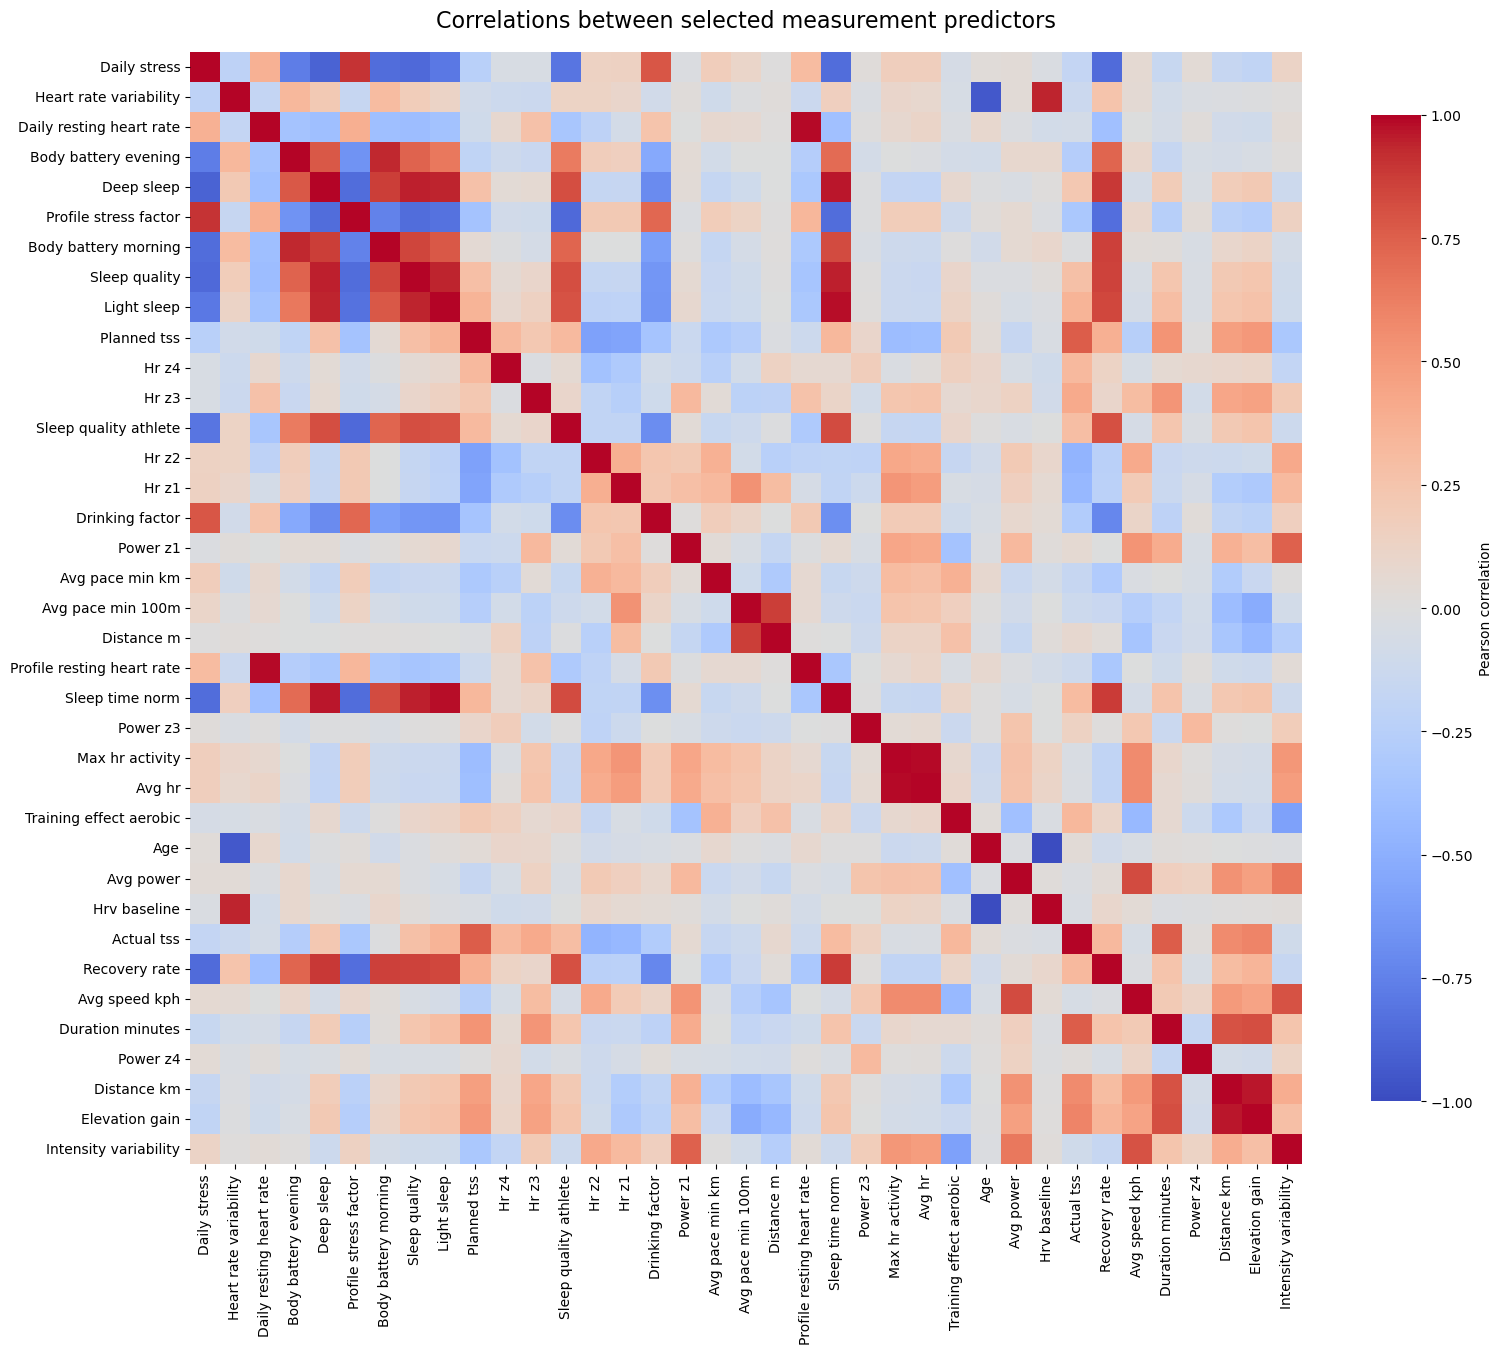

In [33]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Measurements selected by all three feature selection methods
selected_features = [feature
    for feature in all_three_candidates["Feature"]
    if "__" not in feature]

print(f"Measurements included: {len(selected_features)}")

# Correlations between their 14-day summaries
selected_corr = X_selection[selected_features].corr()

# Make labels easier to read
def readable_label(name):
    replacements = {
        "resting_hr": "Daily resting heart rate",
        "resting_hr_athlete": "Profile resting heart rate",
        "hrv": "Heart rate variability",
        "stress": "Daily stress",
        "stress_factor": "Profile stress factor",
        "tss": "Training stress score",
        "ftp": "Functional threshold power",
        "css": "Critical swim speed",
        "vo2max": "VO2 max",}
    return replacements.get(
        name, name.replace("_", " ").replace(".", " ").strip().capitalize())

labels = [readable_label(feature) for feature in selected_features]

# Create the heatmap
fig, ax = plt.subplots(figsize=(16, 14))

sns.heatmap(selected_corr,ax=ax,cmap="coolwarm",vmin=-1,vmax=1,center=0,square=True,xticklabels=labels,yticklabels=labels,
    cbar_kws={"label": "Pearson correlation","shrink": 0.8,},
)

ax.set_title("Correlations between selected measurement predictors",fontsize=16,pad=18,)

plt.setp(ax.get_xticklabels(), rotation=90, fontsize=10)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=10)

fig.tight_layout()
plt.show()

In [34]:
# Show selection counts
display(selection_summary)
print("Inputs compared:", X_selection.shape[1])

,Method,Selected_features
0,Mutual information,97
1,L1 logistic regression,83
2,Random forest,44


Inputs compared: 100


In [35]:
# Keep consensus features and availability indicators
consensus_features = all_three_candidates["Feature"].tolist()
selected_availability = [
    f"{feature}__available" for feature in consensus_features
    if f"{feature}__available" in X_daily.columns
]
selected_features = list(dict.fromkeys(consensus_features + selected_availability))
X_selected_daily = X_daily[selected_features].copy()
print("Consensus measurements:", len(consensus_features))
print("Availability indicators:", len(selected_availability))
print("Total model inputs:", len(selected_features))
print(selected_features)

Consensus measurements: 37
Availability indicators: 15
Total model inputs: 52
['stress', 'hrv', 'resting_hr', 'body_battery_evening', 'deep_sleep', 'stress_factor', 'body_battery_morning', 'sleep_quality', 'light_sleep', 'planned_tss', 'hr_z4', 'hr_z3', 'sleep_quality_athlete', 'hr_z2', 'hr_z1', 'drinking_factor', 'power_z1', 'avg_pace_min_km', 'avg_pace_min_100m', 'distance_m', 'resting_hr_athlete', 'sleep_time_norm', 'power_z3', 'max_hr_activity', 'avg_hr', 'training_effect_aerobic', 'age', 'avg_power', 'hrv_baseline', 'actual_tss', 'recovery_rate', 'avg_speed_kph', 'duration_minutes', 'power_z4', 'distance_km', 'elevation_gain', 'intensity_variability', 'hr_z4__available', 'hr_z3__available', 'hr_z2__available', 'hr_z1__available', 'power_z1__available', 'avg_pace_min_km__available', 'avg_pace_min_100m__available', 'power_z3__available', 'max_hr_activity__available', 'avg_hr__available', 'training_effect_aerobic__available', 'avg_power__available', 'avg_speed_kph__available', 'power

# Modelling

In [36]:
# Split athletes after feature selection
athlete_ids = np.array(sorted(df["athlete_id"].unique()))
rng = np.random.default_rng(42)
rng.shuffle(athlete_ids)
n_train = int(len(athlete_ids) * 0.70)
n_val = int(len(athlete_ids) * 0.15)
train_athletes = set(athlete_ids[:n_train])
val_athletes = set(athlete_ids[n_train:n_train + n_val])
test_athletes = set(athlete_ids[n_train + n_val:])
df["split"] = pd.Series(pd.NA, index=df.index, dtype="string")
df.loc[df["athlete_id"].isin(train_athletes), "split"] = "train"
df.loc[df["athlete_id"].isin(val_athletes), "split"] = "validation"
df.loc[df["athlete_id"].isin(test_athletes), "split"] = "test"
assert df["split"].notna().all()
assert df.groupby("athlete_id")["split"].nunique().eq(1).all()
print(df.groupby("split")["athlete_id"].nunique())

split
test          150
train         700
validation    150
Name: athlete_id, dtype: int64


In [37]:
# Fit scaling on training athletes only
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_selected_daily.loc[df["split"].eq("train")])
X_scaled_daily = pd.DataFrame(
    scaler.transform(X_selected_daily).astype("float32"),
    index=df.index, columns=selected_features
)
assert np.isfinite(X_scaled_daily.to_numpy()).all()
print("Scaled daily inputs:", X_scaled_daily.shape)

Scaled daily inputs: (366000, 52)


**Making the 14-day Sequence**

In [38]:
# Check ordering and daily continuity
assert df.index.equals(pd.RangeIndex(len(df)))
assert X_scaled_daily.index.equals(df.index)
date_gaps = df.groupby("athlete_id")["date"].diff().dropna()
assert date_gaps.eq(pd.Timedelta(days=1)).all()
daily_values = X_scaled_daily.to_numpy(dtype=np.float32)
eligible_values = df["eligible_prediction"].to_numpy()
target_values = df["injury_next_7d"].fillna(-1).to_numpy(dtype=np.int32)

In [41]:
# Build sequences within each athlete
def build_sequences(split_name):
    windows, outcomes, metadata = [], [], []
    split_rows = df.loc[df["split"].eq(split_name)]
    for athlete_id, records in split_rows.groupby("athlete_id", sort=False):
        positions = records.index.to_numpy()
        for end in range(HISTORY_DAYS - 1, len(positions)):
            endpoint = positions[end]
            if not eligible_values[endpoint]:
                continue
            history_positions = positions[end - HISTORY_DAYS + 1:end + 1]
            windows.append(daily_values[history_positions])
            outcomes.append(target_values[endpoint])
            metadata.append((athlete_id, df.at[endpoint, "date"]))
    if not windows:
        raise ValueError(f"No eligible sequences for {split_name}.")
    return (
        np.stack(windows).astype("float32"),
        np.asarray(outcomes, dtype=np.int32),
        pd.DataFrame(metadata, columns=["athlete_id", "prediction_date"])
    )

In [42]:
# Construct model inputs and retain record identifiers
X_train, y_train, train_metadata = build_sequences("train")
X_val, y_val, val_metadata = build_sequences("validation")
X_test, y_test, test_metadata = build_sequences("test")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (222083, 14, 52) (222083,)
Validation: (47550, 14, 52) (47550,)
Test: (47366, 14, 52) (47366,)


**Checking the Inputs**

In [43]:
# Check dimensions, outcomes and athlete separation
datasets = [
    ("Training", X_train, y_train, train_metadata),
    ("Validation", X_val, y_val, val_metadata),
    ("Test", X_test, y_test, test_metadata)
]
summary_rows = []
for name, inputs, outcomes, metadata in datasets:
    assert inputs.shape == (len(outcomes), HISTORY_DAYS, len(selected_features))
    assert len(metadata) == len(outcomes)
    assert np.isfinite(inputs).all()
    assert np.isin(outcomes, [0, 1]).all()
    summary_rows.append({
        "Set": name, "Athletes": metadata["athlete_id"].nunique(),
        "Sequences": len(outcomes), "Positive_outcomes": int(outcomes.sum()),
        "Positive_rate_%": round(outcomes.mean() * 100, 2)
    })
train_ids = set(train_metadata["athlete_id"])
val_ids = set(val_metadata["athlete_id"])
test_ids = set(test_metadata["athlete_id"])
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
sequence_summary = pd.DataFrame(summary_rows)
display(sequence_summary)

,Set,Athletes,Sequences,Positive_outcomes,Positive_rate_%
0,Training,700,222083,21016,9.46
1,Validation,150,47550,4518,9.50
2,Test,150,47366,4751,10.03


## LSTM

In [44]:
# Build an LSTM using the original settings
def build_lstm(units):
    keras.utils.set_random_seed(42)
    model = keras.Sequential([
        layers.Input(shape=(HISTORY_DAYS, X_train.shape[2])),
        layers.LSTM(units),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(curve="PR", name="pr_auc"),
            keras.metrics.AUC(curve="ROC", name="roc_auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall")
        ]
    )
    return model

In [45]:
# Compare hidden-unit counts
lstm_models, lstm_histories, lstm_comparison_rows = {}, {}, []
for units in [16, 32, 64]:
    print(f"\nTraining LSTM with {units} hidden units")
    experiment_model = build_lstm(units)
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_pr_auc", mode="max", patience=3,
        restore_best_weights=True
    )
    experiment_history = experiment_model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=20, batch_size=256, callbacks=[early_stopping],
        shuffle=True, verbose=1
    )
    scores = experiment_model.evaluate(
        X_val, y_val, batch_size=256, return_dict=True, verbose=0
    )
    lstm_models[units] = experiment_model
    lstm_histories[units] = experiment_history.history
    lstm_comparison_rows.append({
        "Hidden_units": units,
        "Parameters": experiment_model.count_params(),
        "Epochs_run": len(experiment_history.history["loss"]),
        "Best_epoch": int(np.argmax(experiment_history.history["val_pr_auc"]) + 1),
        "Validation_loss": scores["loss"],
        "Validation_PR_AUC": scores["pr_auc"],
        "Validation_ROC_AUC": scores["roc_auc"],
        "Precision_at_0.5": scores["precision"],
        "Recall_at_0.5": scores["recall"]
    })


Training LSTM with 16 hidden units
Epoch 1/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.2076 - pr_auc: 0.6265 - precision: 0.8635 - recall: 0.4398 - roc_auc: 0.8261 - val_loss: 0.1621 - val_pr_auc: 0.7348 - val_precision: 0.9008 - val_recall: 0.6113 - val_roc_auc: 0.8500
Epoch 2/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.1671 - pr_auc: 0.7227 - precision: 0.8993 - recall: 0.6011 - roc_auc: 0.8439 - val_loss: 0.1591 - val_pr_auc: 0.7394 - val_precision: 0.9140 - val_recall: 0.6047 - val_roc_auc: 0.8519
Epoch 3/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.1633 - pr_auc: 0.7303 - precision: 0.9076 - recall: 0.6036 - roc_auc: 0.8489 - val_loss: 0.1581 - val_pr_auc: 0.7396 - val_precision: 0.9109 - val_recall: 0.6135 - val_roc_auc: 0.8502
Epoch 4/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.1616 - pr_auc: 0.7336 - precision: 0.9137 - recall: 0.6069 - roc_auc: 0.8499 - val_loss: 0.1572 - val_pr_auc: 0.7422 - val_precision: 0.9213 - val_recall: 0.6065 - 

In [46]:
# Show each trained LSTM architecture
for units, model in lstm_models.items():
    print(f"\nLSTM with {units} hidden units")
    model.summary()


LSTM with 16 hidden units


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         4,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,301 (51.96 KB)

 Trainable params: 4,433 (17.32 KB)

 Non-trainable params: 0 (0.00 B)

... (11 outputs left out)

 Total params: 90,053 (351.77 KB)

 Trainable params: 30,017 (117.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 60,036 (234.52 KB)

In [47]:
# Rank models by restored validation PR-AUC
lstm_units_comparison = pd.DataFrame(lstm_comparison_rows).sort_values(
    ["Validation_PR_AUC", "Hidden_units"], ascending=[False, True]
).reset_index(drop=True)
best_units = int(lstm_units_comparison.iloc[0]["Hidden_units"])
best_lstm_model = lstm_models[best_units]
display(lstm_units_comparison.round(4))
print("Selected hidden units:", best_units)

,Hidden_units,Parameters,Epochs_run,Best_epoch,Validation_loss,Validation_PR_AUC,Validation_ROC_AUC,Precision_at_0.5,Recall_at_0.5
0,16,4433,8,5,0.1567,0.7432,0.8531,0.9186,0.6118
1,32,10913,5,2,0.1580,0.7410,0.8494,0.8959,0.6226
2,64,30017,5,2,0.1592,0.7407,0.8498,0.8973,0.6264


Selected hidden units: 16


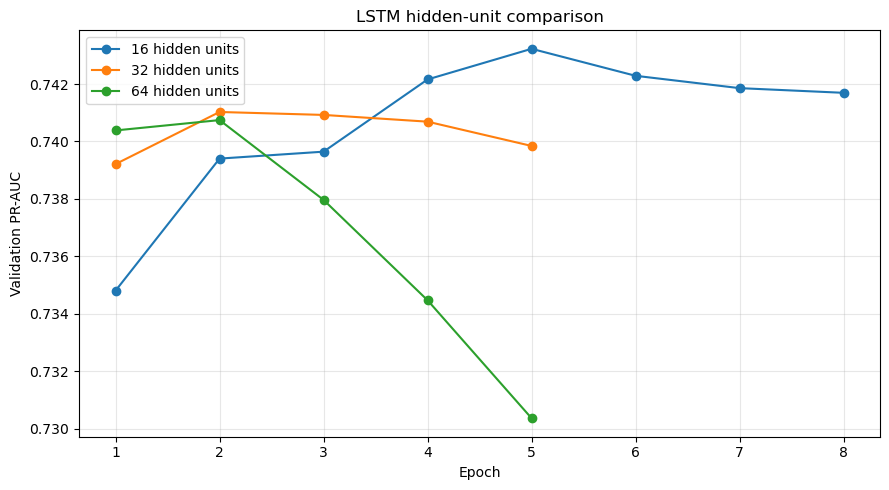

In [48]:
# Compare validation PR-AUC across epochs
fig, ax = plt.subplots(figsize=(9, 5))
for units, history in lstm_histories.items():
    ax.plot(
        range(1, len(history["val_pr_auc"]) + 1),
        history["val_pr_auc"], marker="o", label=f"{units} hidden units"
    )
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation PR-AUC")
ax.set_title("LSTM hidden-unit comparison")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Threshold**

In [49]:
# Import classification measures
from sklearn.metrics import (
    precision_recall_curve, precision_score, recall_score,
    f1_score, confusion_matrix, average_precision_score, roc_auc_score
)

In [50]:
# Predict with restored model weights
lstm_val_probabilities = {}
for units, model in lstm_models.items():
    lstm_val_probabilities[units] = model.predict(
        X_val, batch_size=256, verbose=0
    ).ravel()

In [51]:
# Choose thresholds using validation F1
lstm_selected_thresholds = {}
threshold_results = []
for units, probabilities in lstm_val_probabilities.items():
    precision, recall, thresholds = precision_recall_curve(y_val, probabilities)
    p, r = precision[:-1], recall[:-1]
    f1_values = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
    selected_threshold = float(thresholds[np.argmax(f1_values)])
    lstm_selected_thresholds[units] = selected_threshold
    for setting, threshold in [
        ("Default", 0.5), ("Selected using validation F1", selected_threshold)
    ]:
        predictions = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()
        threshold_results.append({
            "Hidden_units": units, "Setting": setting, "Threshold": threshold,
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0),
            "False_positives": int(fp), "False_negatives": int(fn)
        })
lstm_threshold_comparison = pd.DataFrame(threshold_results)
display(lstm_threshold_comparison.round(4))

,Hidden_units,Setting,Threshold,Precision,Recall,F1,False_positives,False_negatives
0,16,Default,0.5000,0.9186,0.6118,0.7344,245,1754
1,16,Selected using validation F1,0.3313,0.8772,0.6436,0.7425,407,1610
2,32,Default,0.5000,0.8959,0.6226,0.7347,327,1705
3,32,Selected using validation F1,0.3436,0.8584,0.6510,0.7404,485,1577
4,64,Default,0.5000,0.8973,0.6264,0.7377,324,1688
5,64,Selected using validation F1,0.3988,0.8749,0.6456,0.7430,417,1601


In [52]:
# Combine model and threshold results
selected_threshold_rows = lstm_threshold_comparison.loc[
    lstm_threshold_comparison["Setting"].eq("Selected using validation F1")
].drop(columns="Setting")
full_lstm_comparison = lstm_units_comparison.merge(
    selected_threshold_rows, on="Hidden_units", validate="one_to_one"
).sort_values(
    ["Validation_PR_AUC", "Hidden_units"], ascending=[False, True]
).reset_index(drop=True)
best_units = int(full_lstm_comparison.iloc[0]["Hidden_units"])
best_lstm_model = lstm_models[best_units]
best_lstm_threshold = lstm_selected_thresholds[best_units]
display(full_lstm_comparison.round(4))
print("Selected hidden units:", best_units)
print("Selected threshold:", round(best_lstm_threshold, 4))

,Hidden_units,Parameters,Epochs_run,Best_epoch,Validation_loss,Validation_PR_AUC,Validation_ROC_AUC,Precision_at_0.5,Recall_at_0.5,Threshold,Precision,Recall,F1,False_positives,False_negatives
0,16,4433,8,5,0.1567,0.7432,0.8531,0.9186,0.6118,0.3313,0.8772,0.6436,0.7425,407,1610
1,32,10913,5,2,0.1580,0.7410,0.8494,0.8959,0.6226,0.3436,0.8584,0.6510,0.7404,485,1577
2,64,30017,5,2,0.1592,0.7407,0.8498,0.8973,0.6264,0.3988,0.8749,0.6456,0.7430,417,1601


Selected hidden units: 16
Selected threshold: 0.3313


## Simple RNN

In [53]:
# Build the original RNN architecture
keras.utils.set_random_seed(42)
rnn_model = keras.Sequential([
    layers.Input(shape=(HISTORY_DAYS, X_train.shape[2])),
    layers.SimpleRNN(32),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])
rnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(curve="PR", name="pr_auc"),
        keras.metrics.AUC(curve="ROC", name="roc_auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ])
rnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         2,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,753 (10.75 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
# Restore weights from the best validation epoch
rnn_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc", mode="max", patience=3,
    restore_best_weights=True
)
rnn_history = rnn_model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=256, callbacks=[rnn_early_stopping],
    shuffle=True, verbose=1
)

Epoch 1/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.2074 - pr_auc: 0.6534 - precision: 0.6991 - recall: 0.5510 - roc_auc: 0.8272 - val_loss: 0.1608 - val_pr_auc: 0.7339 - val_precision: 0.9041 - val_recall: 0.6135 - val_roc_auc: 0.8516
Epoch 2/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.1659 - pr_auc: 0.7236 - precision: 0.9024 - recall: 0.6042 - roc_auc: 0.8424 - val_loss: 0.1589 - val_pr_auc: 0.7383 - val_precision: 0.8986 - val_recall: 0.6235 - val_roc_auc: 0.8542
Epoch 3/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.1629 - pr_auc: 0.7296 - precision: 0.9058 - recall: 0.6088 - roc_auc: 0.8473 - val_loss: 0.1579 - val_pr_auc: 0.7403 - val_precision: 0.9042 - val_recall: 0.6248 - val_roc_auc: 0.8543
Epoch 4/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1618 - pr_auc: 0.7319 - precision: 0.9085 - recall: 0.6104 - roc_auc: 0.8475 - val_loss: 0.1574 - val_pr_auc: 0.7412 - val_precision: 0.9060 - val_recall: 0.6248 - val_roc_auc: 0.8530
Epoch 5/20
868/8

In [55]:
# Select the threshold using validation F1
rnn_val_probabilities = rnn_model.predict(
    X_val, batch_size=256, verbose=0
).ravel()
precision, recall, thresholds = precision_recall_curve(y_val, rnn_val_probabilities)
p, r = precision[:-1], recall[:-1]
f1_values = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
rnn_selected_threshold = float(thresholds[np.argmax(f1_values)])
rnn_val_predictions = (rnn_val_probabilities >= rnn_selected_threshold).astype(int)
print("Selected RNN threshold:", round(rnn_selected_threshold, 4))

Selected RNN threshold: 0.4015


In [56]:
# Evaluate the restored model and selected threshold
rnn_val_scores = rnn_model.evaluate(
    X_val, y_val, batch_size=256, return_dict=True, verbose=0)
tn, fp, fn, tp = confusion_matrix(
    y_val, rnn_val_predictions, labels=[0, 1]
).ravel()
rnn_validation_results = pd.DataFrame([{
    "Model": "Simple RNN", "Hidden_units": 32,
    "Parameters": rnn_model.count_params(),
    "Epochs_run": len(rnn_history.history["loss"]),
    "Best_epoch": int(np.argmax(rnn_history.history["val_pr_auc"]) + 1),
    "Validation_loss": rnn_val_scores["loss"],
    "Validation_PR_AUC": rnn_val_scores["pr_auc"],
    "Validation_AP": average_precision_score(y_val, rnn_val_probabilities),
    "Validation_ROC_AUC": roc_auc_score(y_val, rnn_val_probabilities),
    "Threshold": rnn_selected_threshold,
    "Precision": precision_score(y_val, rnn_val_predictions, zero_division=0),
    "Recall": recall_score(y_val, rnn_val_predictions, zero_division=0),
    "F1": f1_score(y_val, rnn_val_predictions, zero_division=0),
    "False_positives": int(fp), "False_negatives": int(fn)
}])
display(rnn_validation_results.round(4))

,Model,Hidden_units,Parameters,Epochs_run,Best_epoch,Validation_loss,Validation_PR_AUC,Validation_AP,Validation_ROC_AUC,Threshold,Precision,Recall,F1,False_positives,False_negatives
0,Simple RNN,32,2753,9,6,0.1571,0.7423,0.7423,0.8521,0.4015,0.8859,0.6425,0.7448,374,1615


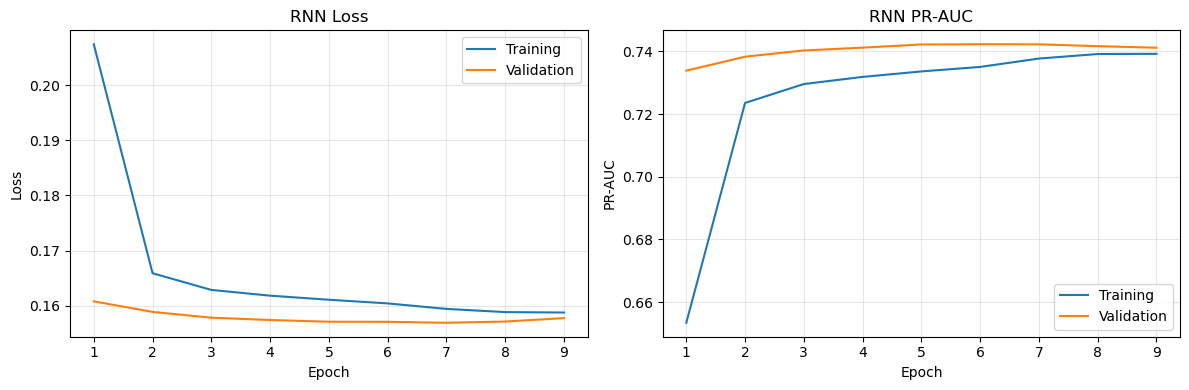

In [57]:
# Inspect loss and PR-AUC during training
epochs = range(1, len(rnn_history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ["loss", "pr_auc"], ["Loss", "PR-AUC"]):
    ax.plot(epochs, rnn_history.history[metric], label="Training")
    ax.plot(epochs, rnn_history.history[f"val_{metric}"], label="Validation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_title(f"RNN {title}")
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 1DCNN

In [58]:
# Build the original CNN architecture
keras.utils.set_random_seed(42)
cnn_model = keras.Sequential([
    layers.Input(shape=(HISTORY_DAYS, X_train.shape[2])),
    layers.Conv1D(filters=32, kernel_size=3, activation="relu", padding="valid"),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(curve="PR", name="pr_auc"),
        keras.metrics.AUC(curve="ROC", name="roc_auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)
cnn_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 12, 32)         │         5,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,057 (19.75 KB)

 Trainable params: 5,057 (19.75 KB)

 Non-trainable params: 0 (0.00 B)

In [59]:
# Restore weights from the best validation epoch
cnn_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc", mode="max", patience=3,
    restore_best_weights=True
)
cnn_history = cnn_model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=256, callbacks=[cnn_early_stopping],
    shuffle=True, verbose=1
)

Epoch 1/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.2273 - pr_auc: 0.5471 - precision: 0.8151 - recall: 0.3206 - roc_auc: 0.8057 - val_loss: 0.1820 - val_pr_auc: 0.6856 - val_precision: 0.8715 - val_recall: 0.5102 - val_roc_auc: 0.8448
Epoch 2/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1874 - pr_auc: 0.6722 - precision: 0.8439 - recall: 0.5249 - roc_auc: 0.8397 - val_loss: 0.1773 - val_pr_auc: 0.6987 - val_precision: 0.8748 - val_recall: 0.5367 - val_roc_auc: 0.8458
Epoch 3/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1825 - pr_auc: 0.6862 - precision: 0.8527 - recall: 0.5434 - roc_auc: 0.8432 - val_loss: 0.1742 - val_pr_auc: 0.7069 - val_precision: 0.8780 - val_recall: 0.5575 - val_roc_auc: 0.8464
Epoch 4/20
868/868 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1797 - pr_auc: 0.6947 - precision: 0.8589 - recall: 0.5514 - roc_auc: 0.8468 - val_loss: 0.1727 - val_pr_auc: 0.7121 - val_precision: 0.8818 - val_recall: 0.5633 - val_roc_auc: 0.8481
Epoch 5/20
868/8

In [60]:
# Select the threshold using validation F1
cnn_val_probabilities = cnn_model.predict(
    X_val, batch_size=256, verbose=0
).ravel()
precision, recall, thresholds = precision_recall_curve(y_val, cnn_val_probabilities)
p, r = precision[:-1], recall[:-1]
f1_values = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
cnn_selected_threshold = float(thresholds[np.argmax(f1_values)])
cnn_val_predictions = (cnn_val_probabilities >= cnn_selected_threshold).astype(int)
print("Selected CNN threshold:", round(cnn_selected_threshold, 4))

Selected CNN threshold: 0.3081


In [61]:
# Evaluate the restored model and selected threshold
cnn_val_scores = cnn_model.evaluate(
    X_val, y_val, batch_size=256, return_dict=True, verbose=0
)
tn, fp, fn, tp = confusion_matrix(
    y_val, cnn_val_predictions, labels=[0, 1]
).ravel()
cnn_validation_results = pd.DataFrame([{
    "Model": "1D CNN", "Filters": 32,
    "Parameters": cnn_model.count_params(),
    "Epochs_run": len(cnn_history.history["loss"]),
    "Best_epoch": int(np.argmax(cnn_history.history["val_pr_auc"]) + 1),
    "Validation_loss": cnn_val_scores["loss"],
    "Validation_PR_AUC": cnn_val_scores["pr_auc"],
    "Validation_AP": average_precision_score(y_val, cnn_val_probabilities),
    "Validation_ROC_AUC": roc_auc_score(y_val, cnn_val_probabilities),
    "Threshold": cnn_selected_threshold,
    "Precision": precision_score(y_val, cnn_val_predictions, zero_division=0),
    "Recall": recall_score(y_val, cnn_val_predictions, zero_division=0),
    "F1": f1_score(y_val, cnn_val_predictions, zero_division=0),
    "False_positives": int(fp), "False_negatives": int(fn)
}])
display(cnn_validation_results.round(4))

,Model,Filters,Parameters,Epochs_run,Best_epoch,Validation_loss,Validation_PR_AUC,Validation_AP,Validation_ROC_AUC,Threshold,Precision,Recall,F1,False_positives,False_negatives
0,1D CNN,32,5057,16,13,0.1689,0.7223,0.7221,0.8461,0.3081,0.8208,0.6368,0.7172,628,1641


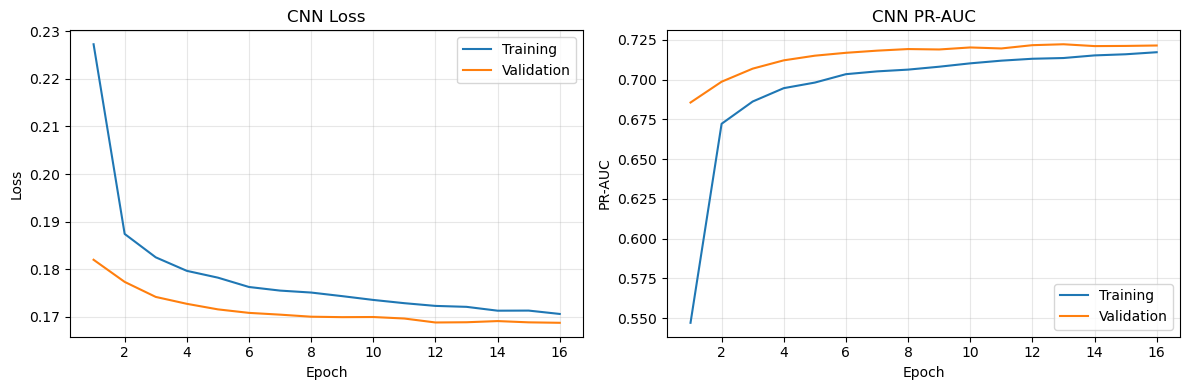

In [62]:
# Inspect loss and PR-AUC during training
epochs = range(1, len(cnn_history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ["loss", "pr_auc"], ["Loss", "PR-AUC"]):
    ax.plot(epochs, cnn_history.history[metric], label="Training")
    ax.plot(epochs, cnn_history.history[f"val_{metric}"], label="Validation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_title(f"CNN {title}")
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Comparison of LSTM, CNN, and RNN**

In [63]:
# Compare models using the same measures
evaluation_models = {
    "LSTM": (best_lstm_model, best_lstm_threshold),
    "Simple RNN": (rnn_model, rnn_selected_threshold),
    "1D CNN": (cnn_model, cnn_selected_threshold)
}
validation_probabilities = {
    "LSTM": lstm_val_probabilities[best_units],
    "Simple RNN": rnn_val_probabilities,
    "1D CNN": cnn_val_probabilities
}
validation_rows = []
for name, probabilities in validation_probabilities.items():
    threshold = evaluation_models[name][1]
    predictions = (probabilities >= threshold).astype(int)
    validation_rows.append({
        "Model": name, "Threshold": threshold,
        "Average_precision": average_precision_score(y_val, probabilities),
        "ROC_AUC": roc_auc_score(y_val, probabilities),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0)
    })
validation_comparison = pd.DataFrame(validation_rows)
display(validation_comparison.round(4))

,Model,Threshold,Average_precision,ROC_AUC,Precision,Recall,F1
0,LSTM,0.3313,0.7430,0.8525,0.8772,0.6436,0.7425
1,Simple RNN,0.4015,0.7423,0.8521,0.8859,0.6425,0.7448
2,1D CNN,0.3081,0.7221,0.8461,0.8208,0.6368,0.7172


In [64]:
# Predict test outcomes with fixed models
test_probabilities_by_model = {}
for name, (model, threshold) in evaluation_models.items():
    test_probabilities_by_model[name] = model.predict(
        X_test, batch_size=256, verbose=0
    ).ravel()

In [65]:
# Calculate test measures at fixed thresholds
test_rows = []
for name, probabilities in test_probabilities_by_model.items():
    threshold = evaluation_models[name][1]
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    test_rows.append({
        "Model": name, "Threshold": threshold,
        "Average_precision": average_precision_score(y_test, probabilities),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "True_negatives": int(tn), "False_positives": int(fp),
        "False_negatives": int(fn), "True_positives": int(tp)
    })
test_comparison = pd.DataFrame(test_rows)
display(test_comparison.round(4))

,Model,Threshold,Average_precision,ROC_AUC,Precision,Recall,F1,True_negatives,False_positives,False_negatives,True_positives
0,LSTM,0.3313,0.7275,0.8390,0.8795,0.6192,0.7268,42212,403,1809,2942
1,Simple RNN,0.4015,0.7265,0.8370,0.8850,0.6201,0.7292,42232,383,1805,2946
2,1D CNN,0.3081,0.7053,0.8337,0.8299,0.6131,0.7052,42018,597,1838,2913


Files saved in: C:\Users\santo\OneDrive\Documents\repos\MATH1332-Minor-Thesis-Semester-2-2026\output\confusion_matrices


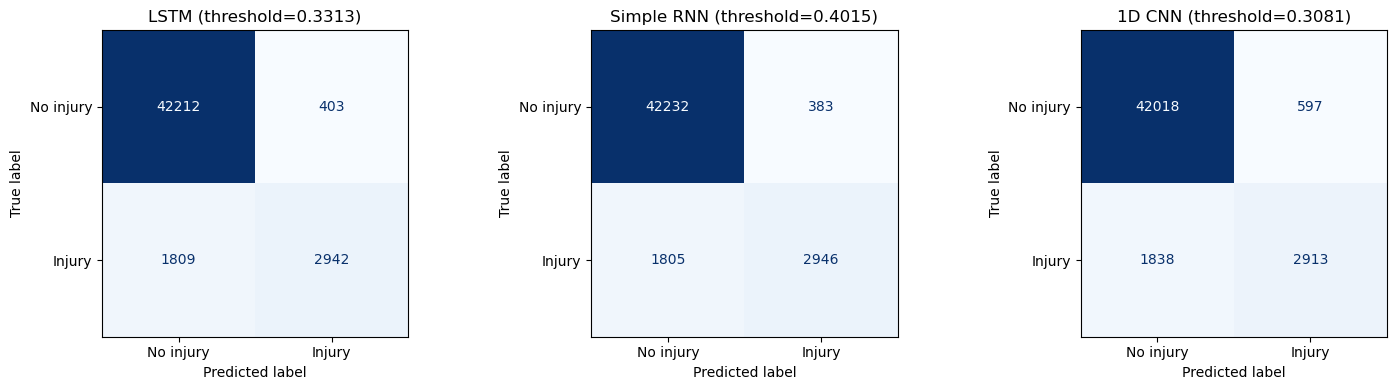

In [66]:
# Show correct and incorrect test predictions
from sklearn.metrics import ConfusionMatrixDisplay
confusion_fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, probabilities) in zip(axes, test_probabilities_by_model.items()):
    threshold = evaluation_models[name][1]
    predictions = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(
        matrix, display_labels=["No injury", "Injury"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} (threshold={threshold:.4f})")
confusion_fig.tight_layout()
from pathlib import Path

output_folder = Path("output") / "confusion_matrices"
output_folder.mkdir(parents=True, exist_ok=True)

confusion_fig.savefig(
    output_folder / "test_confusion_matrices.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

confusion_fig.savefig(
    output_folder / "test_confusion_matrices.svg",
    bbox_inches="tight",
    facecolor="white"
)

print(f"Files saved in: {output_folder.resolve()}")

plt.show()

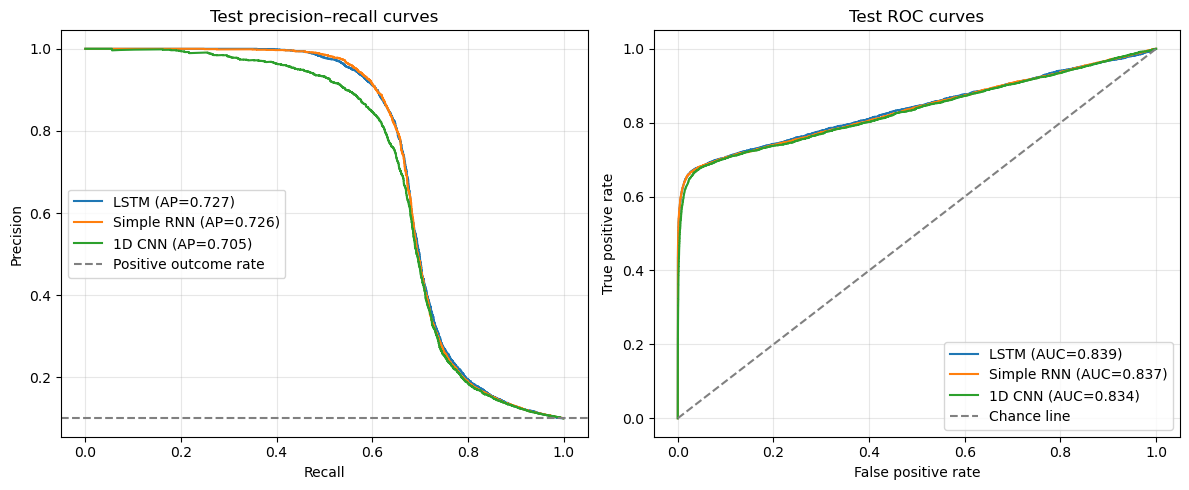

In [67]:
# Compare performance across thresholds
from sklearn.metrics import roc_curve
curve_fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, probabilities in test_probabilities_by_model.items():
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    axes[0].plot(recall, precision, label=f"{name} (AP={ap:.3f})")
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
axes[0].axhline(y_test.mean(), color="grey", linestyle="--", label="Positive outcome rate")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Chance line")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Test precision–recall curves")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="Test ROC curves")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
curve_fig.tight_layout()
plt.show()

## Explainable Machine Learning - 128 sample

In [68]:
explain_model = best_lstm_model
explain_feature_names = list(selected_features)
explain_rng = np.random.default_rng(42)

# Selecting 8 training windows as reference examples.
reference_indices = explain_rng.choice(
    len(X_train),
    size=min(8, len(X_train)),
    replace=False
)

reference_windows = X_train[reference_indices]

# Selecting up to 128 validation windows to explain.
explain_indices = explain_rng.choice(
    len(X_val),
    size=min(128, len(X_val)),
    replace=False
)

explain_windows = X_val[explain_indices]

print("Reference windows:", reference_windows.shape)
print("Windows to explain:", explain_windows.shape)
print("Number of features:", len(explain_feature_names))

Reference windows: (8, 14, 52)
Windows to explain: (128, 14, 52)
Number of features: 52


In [69]:
#Calculating predictions before explaining them

reference_probabilities = explain_model.predict(
    reference_windows,
    verbose=0
).ravel()

explain_probabilities = explain_model.predict(
    explain_windows,
    verbose=0
).ravel()

# Comparison point
reference_mean_probability = reference_probabilities.mean()

# threshold selected
explain_threshold = best_lstm_threshold

print(
    f"Mean reference probability: "
    f"{reference_mean_probability:.4f}"
)
print(f"Selected threshold: {explain_threshold:.4f}")

explanation_preview = pd.DataFrame({
    "Validation_window_index": explain_indices,
    "Actual_outcome": np.asarray(y_val)[explain_indices].astype(int),
    "Predicted_probability": explain_probabilities,
    "Predicted_class": (
        explain_probabilities >= explain_threshold
    ).astype(int),
    "Difference_from_reference": (
        explain_probabilities - reference_mean_probability
    )
})

display(explanation_preview.head(10).round(4))

Mean reference probability: 0.2685
Selected threshold: 0.3313


,Validation_window_index,Actual_outcome,Predicted_probability,Predicted_class,Difference_from_reference
0,40720,0,0.0267,0,-0.2419
1,20759,0,0.0451,0,-0.2234
2,16522,0,0.0323,0,-0.2363
3,32421,0,0.0358,0,-0.2328
4,42989,0,0.0234,0,-0.2452
5,31807,0,0.0251,0,-0.2435
6,42660,0,0.0325,0,-0.2360
7,36364,0,0.0475,0,-0.2210
8,39027,0,0.0348,0,-0.2337
9,37859,0,0.0257,0,-0.2428


In [70]:
# Calculate Integrated Gradients

def integrated_gradients(model, windows, reference, steps=64):
    """Calculate feature-by-day contributions relative to one reference."""

    contributions = np.zeros_like(windows, dtype=np.float32)

    alphas = np.linspace(0, 1, steps + 1, dtype=np.float32)

    # Trapezoidal integration gives the endpoints half weight.
    weights = np.ones(steps + 1, dtype=np.float32)
    weights[0] = 0.5
    weights[-1] = 0.5

    # Process small batches to limit memory use.
    for start in range(0, len(windows), 16):
        batch = np.asarray(
            windows[start:start + 16],
            dtype=np.float32
        )

        difference = batch - reference
        gradient_sum = np.zeros_like(batch)

        for position in range(0, len(alphas), 8):
            alpha_batch = alphas[position:position + 8]

            interpolated = (
                reference
                + alpha_batch[:, None, None, None]
                * difference[None, ...]
            )

            inputs = tf.convert_to_tensor(
                interpolated.reshape((-1,) + batch.shape[1:]),
                dtype=tf.float32
            )

            # Measure how the predicted probability changes
            with tf.GradientTape() as tape:
                tape.watch(inputs)
                probabilities = model(inputs, training=False)
                total_probability = tf.reduce_sum(probabilities[:, 0])

            gradients = tape.gradient(total_probability, inputs)

            if gradients is None:
                raise RuntimeError("Could not calculate input gradients.")

            gradients = gradients.numpy().reshape(interpolated.shape)

            gradient_sum += np.sum(
                gradients
                * weights[position:position + 8, None, None, None],
                axis=0
            )

        contributions[start:start + len(batch)] = (
            difference * gradient_sum / steps
        )

    return contributions


# Average contributions across the training references.
feature_contributions = np.zeros_like(
    explain_windows,
    dtype=np.float32
)

for reference_number, reference in enumerate(reference_windows, start=1):
    print(
        f"Processing reference "
        f"{reference_number}/{len(reference_windows)}",
        flush=True
    )

    feature_contributions += integrated_gradients(
        explain_model,
        explain_windows,
        reference,
        steps=64
    ) / len(reference_windows)

print("\nContribution array shape:", feature_contributions.shape)

Processing reference 1/8
Processing reference 2/8
Processing reference 3/8
Processing reference 4/8
Processing reference 5/8
Processing reference 6/8
Processing reference 7/8
Processing reference 8/8

Contribution array shape: (128, 14, 52)


In [71]:
# Numerical accuracy of the explanations

total_contributions = feature_contributions.sum(axis=(1, 2))
reconstructed_probabilities = (
    reference_mean_probability + total_contributions
)

absolute_errors = np.abs(
    explain_probabilities - reconstructed_probabilities
)

completeness_check = pd.DataFrame({
    "Validation_window_index": explain_indices,
    "Predicted_probability": explain_probabilities,
    "Reference_probability": reference_mean_probability,
    "Total_contribution": total_contributions,
    "Reconstructed_probability": reconstructed_probabilities,
    "Absolute_error": absolute_errors
})

display(completeness_check.head(10).round(6))

print(f"Mean absolute error: {absolute_errors.mean():.6f}")
print(f"Maximum absolute error: {absolute_errors.max():.6f}")

# Practical numerical tolerance: 0.005 probability = 0.5 percentage points.
explanations_pass_check = bool(
    np.isfinite(feature_contributions).all()
    and np.isfinite(absolute_errors).all()
    and absolute_errors.max() <= 0.005
)

if explanations_pass_check:
    print("\nCheck passed: ready to plot feature contributions.")
else:
    print(
        "\nCheck failed: increase steps=64 to steps=128 "
        "in the previous cell, rerun it, then repeat this check."
    )

,Validation_window_index,Predicted_probability,Reference_probability,Total_contribution,Reconstructed_probability,Absolute_error
0,40720,0.026682,0.268534,-0.241848,0.026686,0.000004
1,20759,0.045118,0.268534,-0.223402,0.045132,0.000014
2,16522,0.032261,0.268534,-0.236271,0.032263,0.000002
3,32421,0.035759,0.268534,-0.232765,0.035770,0.000011
4,42989,0.023368,0.268534,-0.245163,0.023372,0.000003
5,31807,0.025070,0.268534,-0.243461,0.025073,0.000003
6,42660,0.032542,0.268534,-0.235983,0.032551,0.000009
7,36364,0.047516,0.268534,-0.221005,0.047529,0.000013
8,39027,0.034833,0.268534,-0.233697,0.034837,0.000004
9,37859,0.025740,0.268534,-0.242791,0.025743,0.000003


Mean absolute error: 0.000010
Maximum absolute error: 0.000093

Check passed: ready to plot feature contributions.


,Feature,Mean_absolute_contribution
0,stress,0.016812
1,hrv,0.005692
2,resting_hr,0.004779
3,resting_hr_athlete,0.004374
4,stress_factor,0.004361
5,body_battery_evening,0.003523
6,drinking_factor,0.002641
7,hrv_baseline,0.002577
8,light_sleep,0.002290
9,avg_speed_kph,0.002287


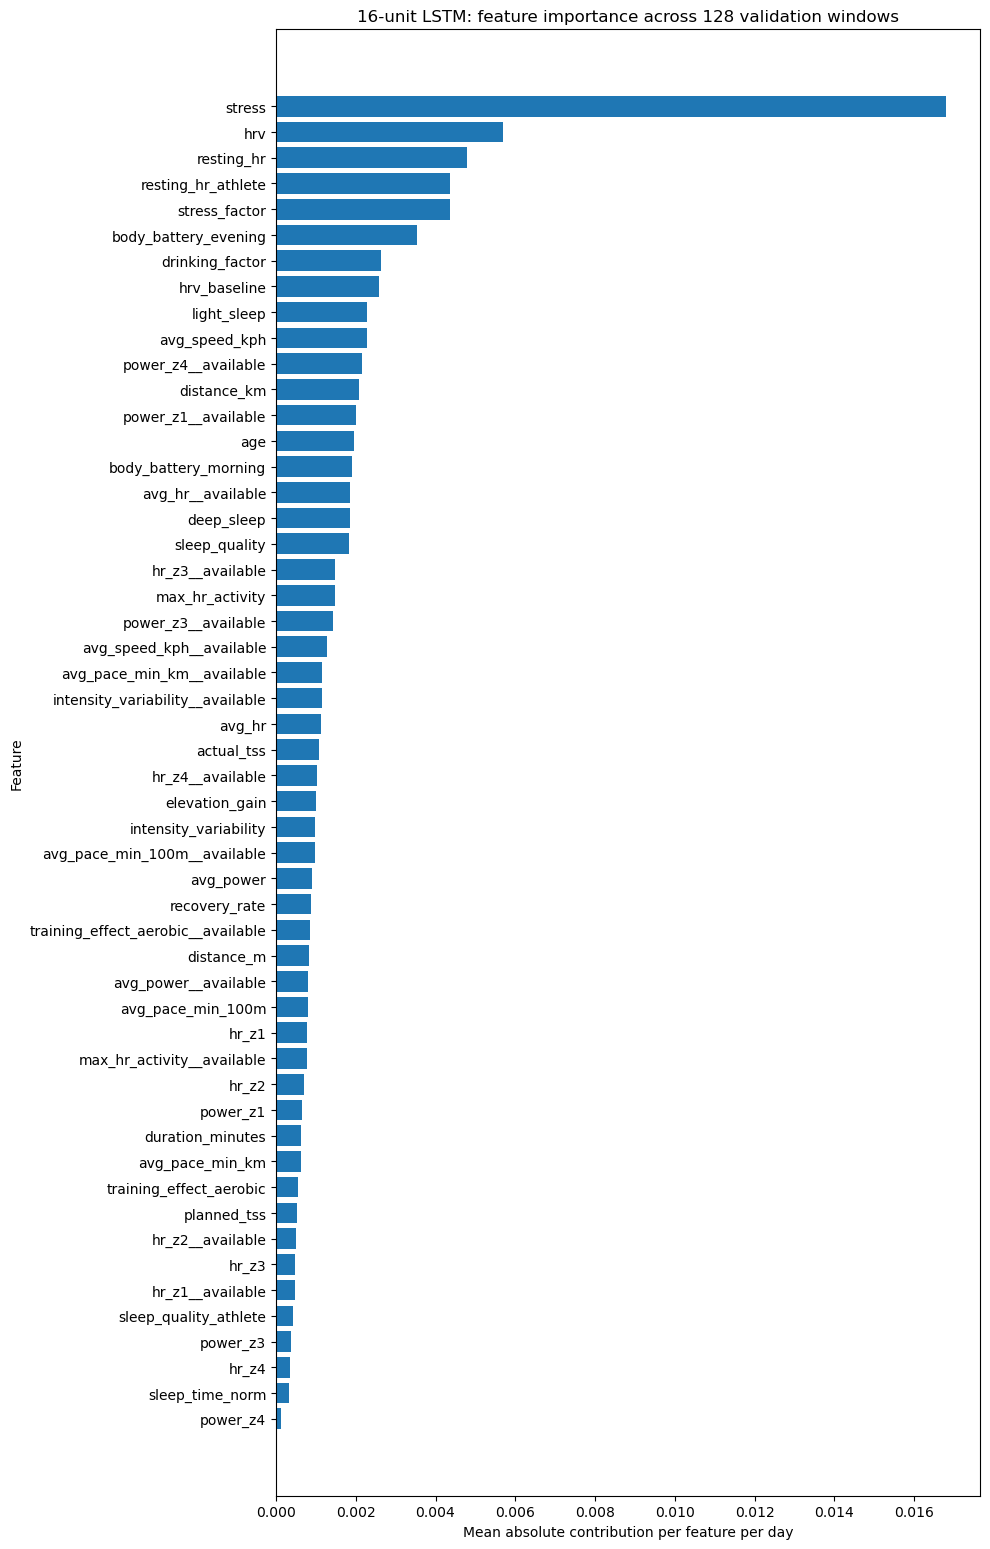

In [72]:
# overall feature importance

if not explanations_pass_check:
    raise ValueError("Complete the numerical accuracy check first.")

# Take absolute values before
mean_absolute_contributions = np.abs(
    feature_contributions
).mean(axis=(0, 1))

feature_importance = (
    pd.DataFrame({
        "Feature": explain_feature_names,
        "Mean_absolute_contribution": mean_absolute_contributions
    })
    .sort_values(
        "Mean_absolute_contribution",
        ascending=False
    )
    .reset_index(drop=True)
)

display(feature_importance.round(6))

# Reverse the order so the most important feature appears at the top.
plot_data = feature_importance.iloc[::-1]

plt.figure(figsize=(10, max(5, len(plot_data) * 0.3)))

plt.barh(
    plot_data["Feature"],
    plot_data["Mean_absolute_contribution"]
)

plt.xlabel("Mean absolute contribution per feature per day")
plt.ylabel("Feature")
plt.title("16-unit LSTM: feature importance across 128 validation windows")
plt.tight_layout()
from pathlib import Path

output_folder = Path("output") / "integrated gradients"
output_folder.mkdir(parents=True, exist_ok=True)
plt.savefig(
    output_folder / "feauture.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.show()

Validation window index: 22391
Predicted probability: 0.9973
Selected threshold: 0.3313
Predicted class: 1
Actual outcome: 1
Mean reference probability: 0.2685


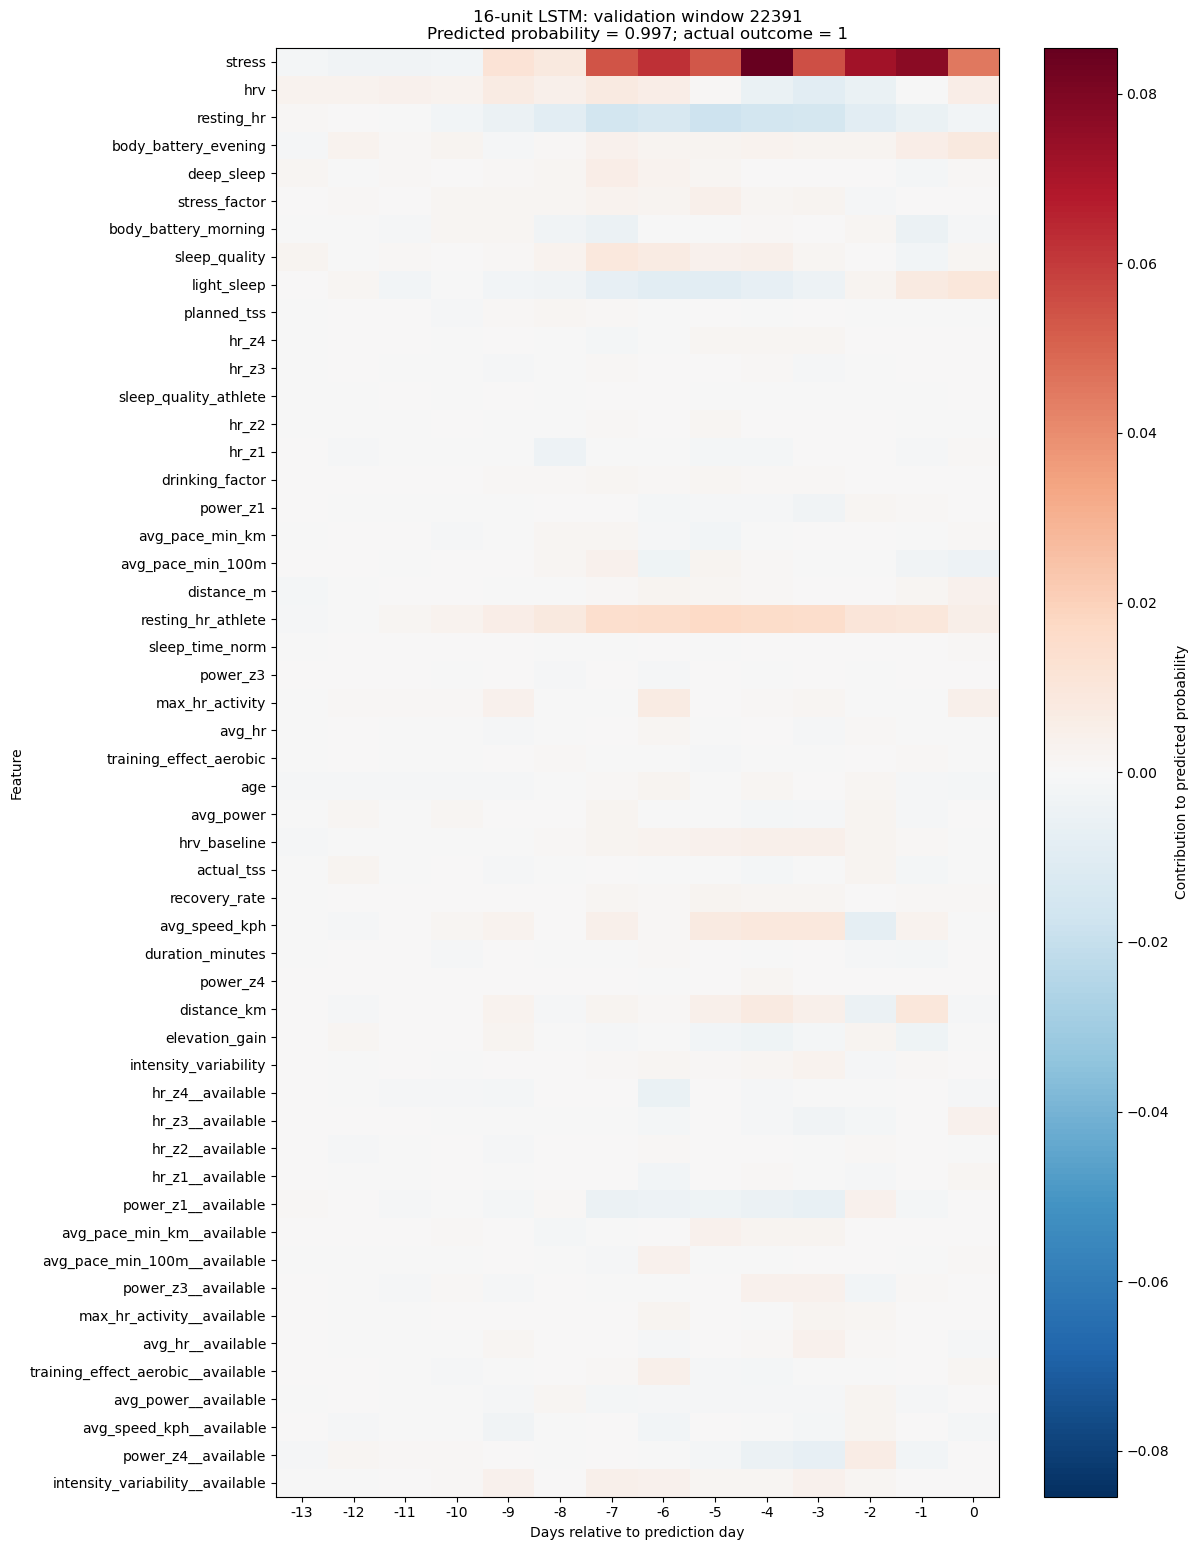

In [73]:
# one high-probability prediction

# Select the highest-probability window in our sample.
example_index = int(np.argmax(explain_probabilities))
validation_index = int(explain_indices[example_index])

probability = float(explain_probabilities[example_index])
actual_outcome = int(np.asarray(y_val)[validation_index])
predicted_class = int(probability >= explain_threshold)

print("Validation window index:", validation_index)
print(f"Predicted probability: {probability:.4f}")
print(f"Selected threshold: {explain_threshold:.4f}")
print("Predicted class:", predicted_class)
print("Actual outcome:", actual_outcome)
print(f"Mean reference probability: {reference_mean_probability:.4f}")

# Transpose from (days, features) to (features, days).
contributions = feature_contributions[example_index].T

colour_limit = max(float(np.abs(contributions).max()), 1e-8)
day_labels = np.arange(-(explain_windows.shape[1] - 1), 1)

fig, ax = plt.subplots(figsize=(12, max(6, len(explain_feature_names) * 0.3)))

heatmap = ax.imshow(
    contributions,
    cmap="RdBu_r",
    vmin=-colour_limit,
    vmax=colour_limit,
    aspect="auto")

ax.set_xticks(range(len(day_labels)))
ax.set_xticklabels(day_labels)

ax.set_yticks(range(len(explain_feature_names)))
ax.set_yticklabels(explain_feature_names)

ax.set_xlabel("Days relative to prediction day")
ax.set_ylabel("Feature")
ax.set_title(
    f"16-unit LSTM: validation window {validation_index}\n"
    f"Predicted probability = {probability:.3f}; "
    f"actual outcome = {actual_outcome}")

fig.colorbar(heatmap,ax=ax,label="Contribution to predicted probability")
plt.tight_layout()
plt.show()

False positives in sample: 1
False negatives in sample: 4


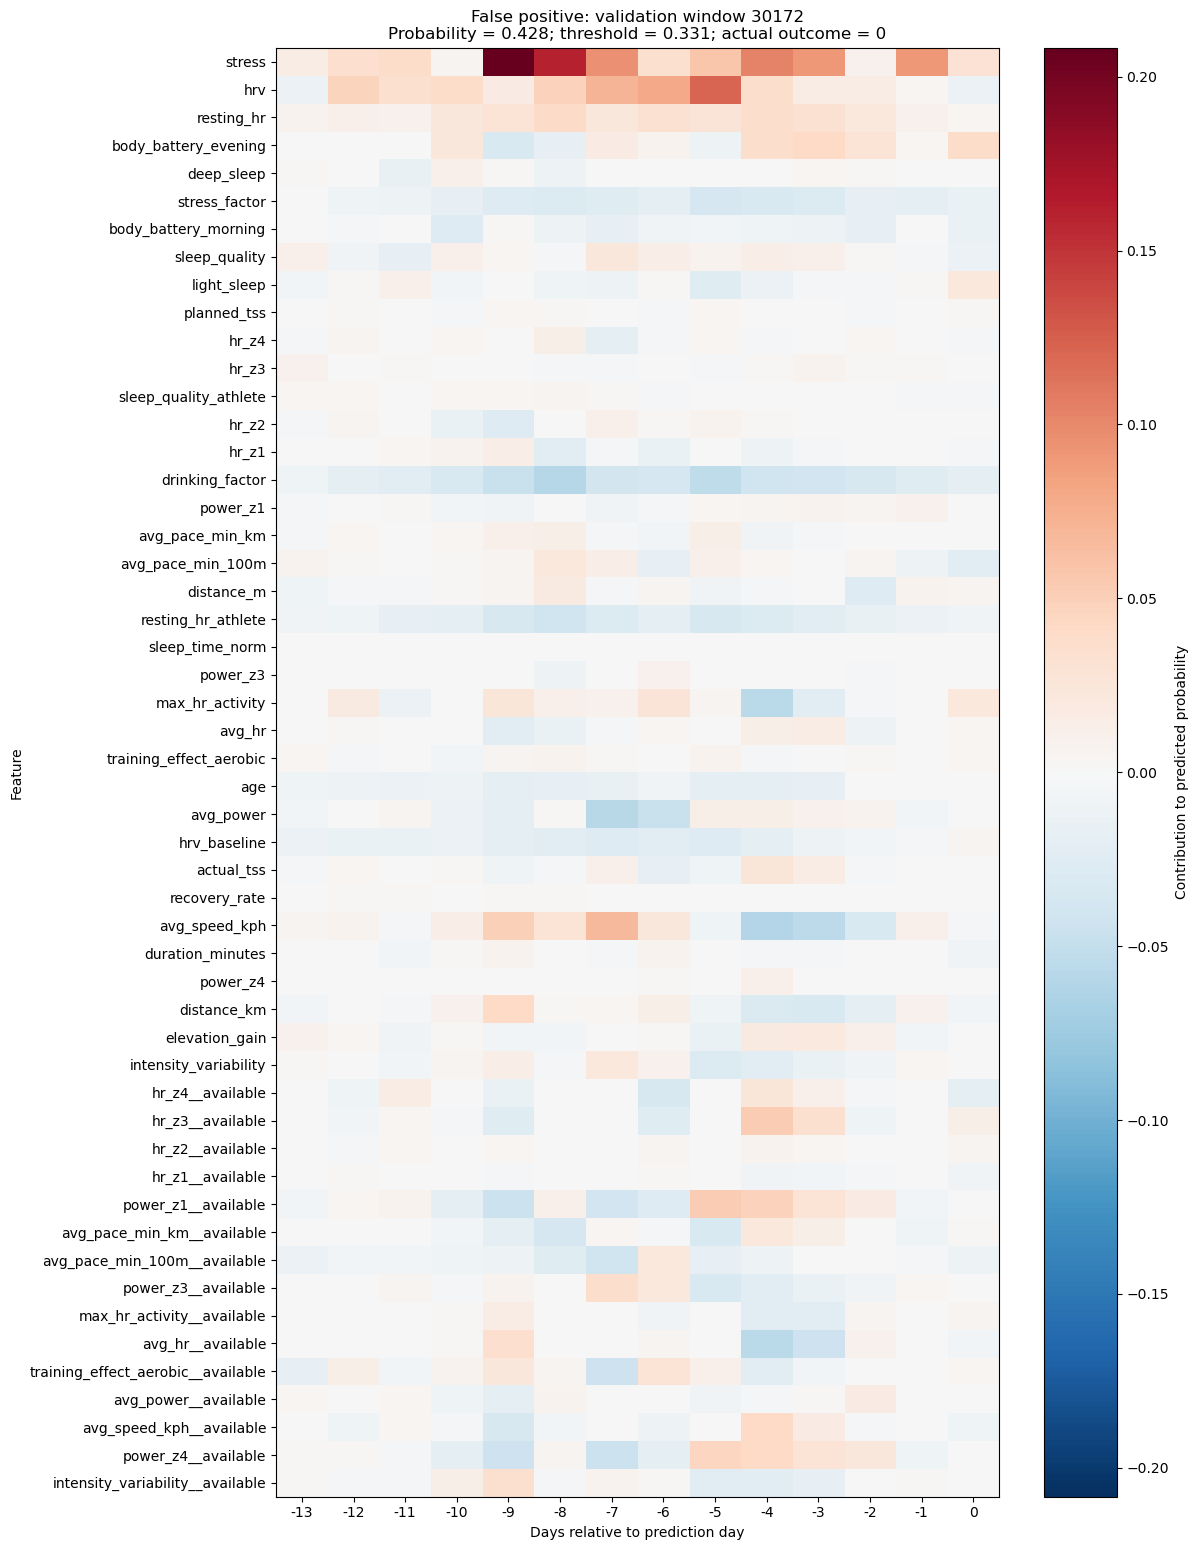

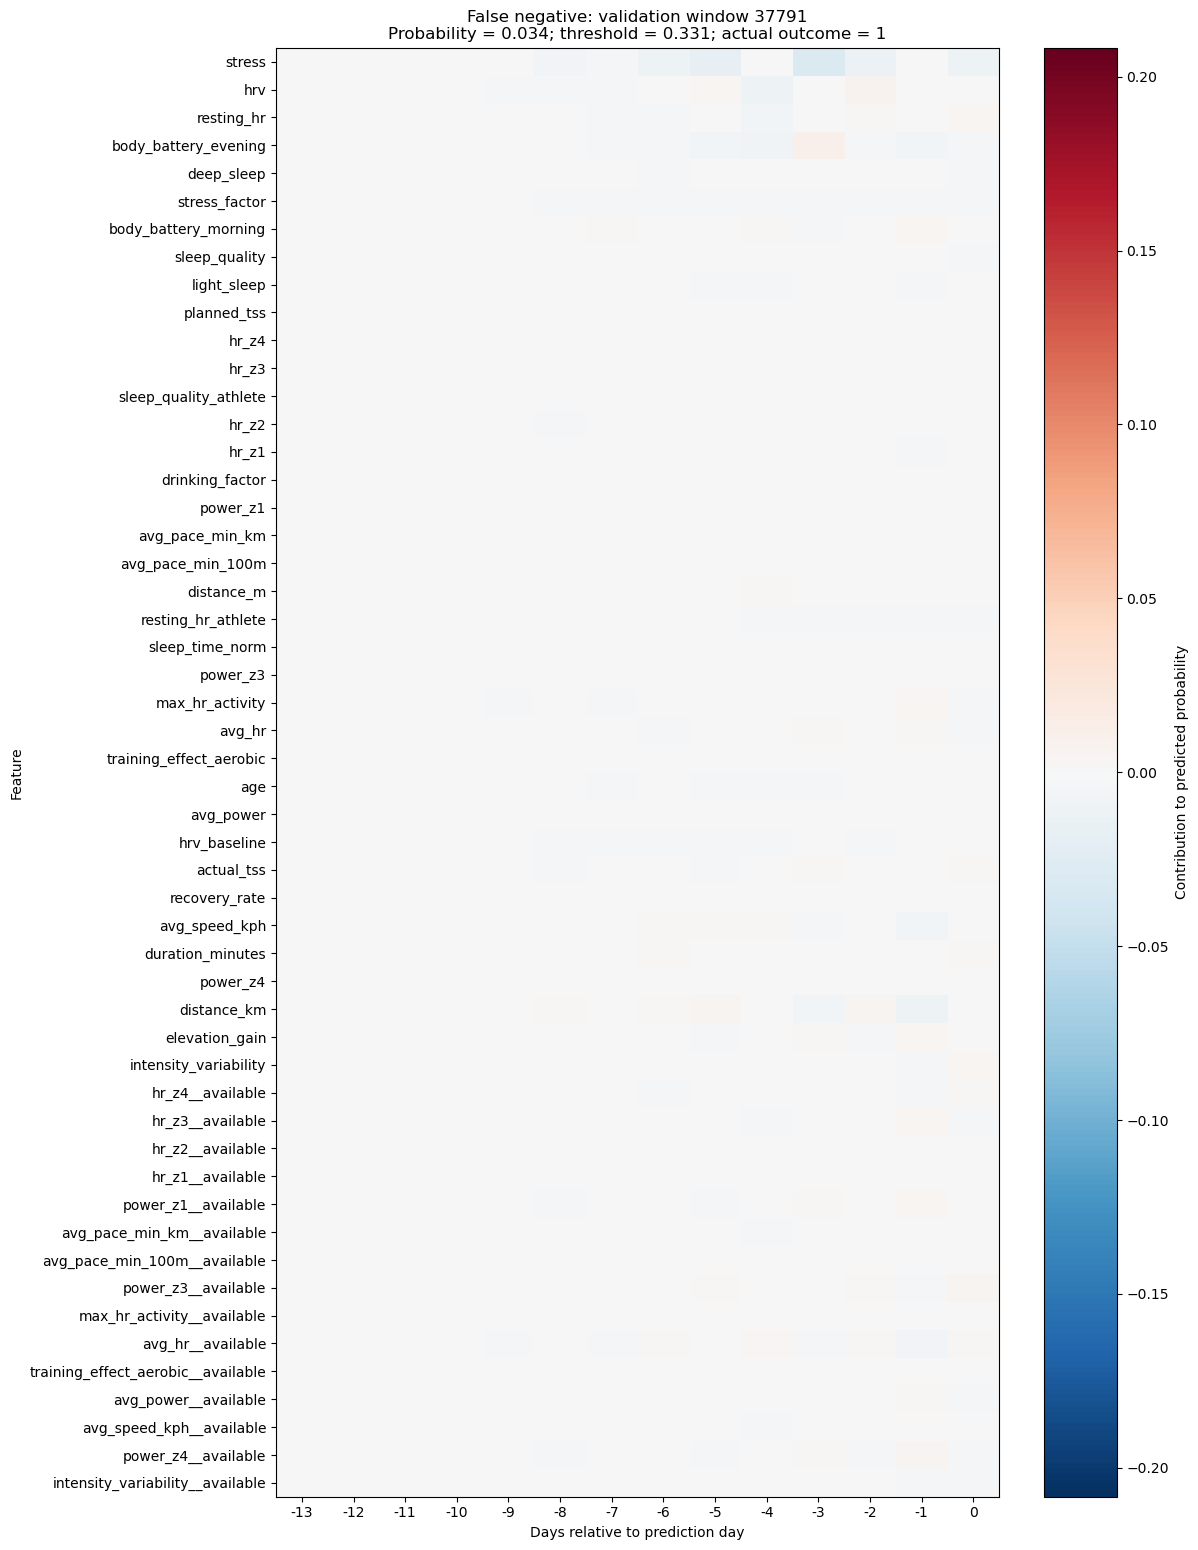

Files saved in: C:\Users\santo\OneDrive\Documents\repos\MATH1332-Minor-Thesis-Semester-2-2026\output\mistake_explanations


In [74]:
#save examples where the model made mistakes

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Create the output folder
output_folder = Path("output") / "mistake_explanations"
output_folder.mkdir(parents=True, exist_ok=True)

sample_actual = np.asarray(y_val)[explain_indices].astype(int)

sample_predicted = (
    explain_probabilities >= explain_threshold
).astype(int)

false_positive_indices = np.flatnonzero(
    (sample_actual == 0) & (sample_predicted == 1)
)

false_negative_indices = np.flatnonzero(
    (sample_actual == 1) & (sample_predicted == 0)
)

print("False positives in sample:", len(false_positive_indices))
print("False negatives in sample:", len(false_negative_indices))

mistake_examples = []

# Select the highest-scoring false positive in the sample.
if len(false_positive_indices):
    index = false_positive_indices[
        np.argmax(explain_probabilities[false_positive_indices])]
    mistake_examples.append(("False positive", int(index)))

# Select the lowest-scoring false negative in the sample.
if len(false_negative_indices):
    index = false_negative_indices[
        np.argmin(explain_probabilities[false_negative_indices])]
    mistake_examples.append(("False negative", int(index)))

if mistake_examples:

    # Use the same colour scale for both heatmaps.
    colour_limit = max(
        max(float(np.abs(feature_contributions[index]).max())
            for _, index in mistake_examples
        ),
        1e-8
    )

    day_labels = np.arange(
        -(explain_windows.shape[1] - 1), 1)

    for label, index in mistake_examples:
        validation_index = int(explain_indices[index])
        probability = float(explain_probabilities[index])

        fig, ax = plt.subplots(figsize=(12, max(6, len(explain_feature_names) * 0.3)))

        heatmap = ax.imshow(
            feature_contributions[index].T,
            cmap="RdBu_r",
            vmin=-colour_limit,
            vmax=colour_limit,
            aspect="auto")

        ax.set_xticks(range(len(day_labels)))
        ax.set_xticklabels(day_labels)
        ax.set_yticks(range(len(explain_feature_names)))
        ax.set_yticklabels(explain_feature_names)

        ax.set_xlabel("Days relative to prediction day")
        ax.set_ylabel("Feature")
        ax.set_title(
            f"{label}: validation window {validation_index}\n"
            f"Probability = {probability:.3f}; "
            f"threshold = {explain_threshold:.3f}; "
            f"actual outcome = {sample_actual[index]}")

        fig.colorbar(heatmap,ax=ax,label="Contribution to predicted probability")

        fig.tight_layout()

        # Give each example a separate filename.
        filename = (
            f"{label.lower().replace(' ', '_')}"
            f"_window_{validation_index}"
        )

        # Save a high-resolution PNG for Word.
        fig.savefig(
            output_folder / f"{filename}.png",
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
        )

        # Save an SVG that stays sharp when resized.
        fig.savefig(
            output_folder / f"{filename}.svg",
            bbox_inches="tight",
            facecolor="white"
        )

        plt.show()
        plt.close(fig)

    print(f"Files saved in: {output_folder.resolve()}")

else:
    print("No misclassified windows in this sample.")

In [75]:
# Compare measured stress with its contribution for the lowest-probability false negative

if len(false_negative_indices) == 0:
    print("There are no false negatives in this sample.")
else:
    fn_index = int(
        false_negative_indices[
            np.argmin(explain_probabilities[false_negative_indices])
        ]
    )

    stress_index = explain_feature_names.index("stress")

    # Undo standardisation to recover the original feature values.
    original_window = scaler.inverse_transform(
        explain_windows[fn_index])

    # Recover the original values in the training reference windows.
    original_references = scaler.inverse_transform(
        reference_windows.reshape(-1, len(explain_feature_names))
    ).reshape(reference_windows.shape)

    stress_comparison = pd.DataFrame({
        "Day": np.arange(-(explain_windows.shape[1] - 1), 1),
        "Stress_value": original_window[:, stress_index],
        "Mean_reference_stress": (
            original_references[:, :, stress_index].mean(axis=0)
        ),
        "Stress_contribution": (
            feature_contributions[fn_index, :, stress_index]
        )
    })

    display(stress_comparison.round(4))

,Day,Stress_value,Mean_reference_stress,Stress_contribution
0,-13,21.200001,23.775000,0.0003
1,-12,25.000000,26.137501,0.0007
2,-11,25.400000,21.212500,0.0016
3,-10,24.400000,24.858801,-0.0016
4,-9,23.900000,22.121700,-0.0009
5,-8,23.799999,25.209400,-0.0058
6,-7,26.700001,27.318501,-0.0020
7,-6,22.900000,27.951401,-0.0104
8,-5,23.400000,27.948999,-0.0170
9,-4,33.900002,28.493601,0.0003


In [76]:
# second reference sample for stability check

stability_rng = np.random.default_rng(123)

# Exclude the original references so the new sample is different.
available_indices = np.setdiff1d(
    np.arange(len(X_train)),
    reference_indices)

if len(available_indices) < len(reference_indices):
    raise ValueError("Not enough training windows for a separate reference sample.")

stability_reference_indices = stability_rng.choice(
    available_indices,
    size=len(reference_indices),
    replace=False)

stability_reference_windows = X_train[stability_reference_indices]

print("Original reference indices:", reference_indices)
print("New reference indices:", stability_reference_indices)
print("New reference shape:", stability_reference_windows.shape)
print("Validation windows remain unchanged:", explain_windows.shape)

Original reference indices: [ 19086 154873 190678 145365  96164  97465  19820 171877]
New reference indices: [ 11952   3428  48937  56650 201890  40946 151534 131679]
New reference shape: (8, 14, 52)
Validation windows remain unchanged: (128, 14, 52)


In [77]:
# Recalculate contributions with the new references

stability_contributions = np.zeros_like(
    explain_windows,
    dtype=np.float32)

for number, reference in enumerate(
    stability_reference_windows, start=1):
    print(
        f"Processing new reference "
        f"{number}/{len(stability_reference_windows)}",
        flush=True)

    stability_contributions += integrated_gradients(explain_model,explain_windows,reference,steps=64
    ) / len(stability_reference_windows)

# numerical accuracy against the NEW reference probability.
stability_reference_mean = float(
    explain_model.predict(stability_reference_windows,verbose=0).mean())

stability_reconstructed = (stability_reference_mean+ stability_contributions.sum(axis=(1, 2)))

stability_errors = np.abs(explain_probabilities - stability_reconstructed)

stability_passed = bool(
    np.isfinite(stability_contributions).all()
    and np.isfinite(stability_errors).all()
    and stability_errors.max() <= 0.005)

print(f"\nNew reference mean probability: {stability_reference_mean:.6f}")
print(f"Mean absolute error: {stability_errors.mean():.6f}")
print(f"Maximum absolute error: {stability_errors.max():.6f}")
print("Numerical check passed:", stability_passed)

Processing new reference 1/8
Processing new reference 2/8
Processing new reference 3/8
Processing new reference 4/8
Processing new reference 5/8
Processing new reference 6/8
Processing new reference 7/8
Processing new reference 8/8

New reference mean probability: 0.027149
Mean absolute error: 0.000003
Maximum absolute error: 0.000113
Numerical check passed: True


,Feature,Original_importance,New_importance,Original_rank,New_rank,Rank_change
0,stress,0.016812,0.008302,1.0,1.0,0.0
1,hrv,0.005692,0.003265,2.0,2.0,0.0
2,resting_hr,0.004779,0.002894,3.0,4.0,1.0
3,resting_hr_athlete,0.004374,0.002713,4.0,5.0,1.0
4,stress_factor,0.004361,0.003134,5.0,3.0,-2.0
5,body_battery_evening,0.003523,0.001934,6.0,6.0,0.0
6,drinking_factor,0.002641,0.001774,7.0,7.0,0.0
7,hrv_baseline,0.002577,0.001301,8.0,9.0,1.0
8,light_sleep,0.002290,0.001482,9.0,8.0,-1.0
9,avg_speed_kph,0.002287,0.001163,10.0,16.0,6.0



Rank correlation: 0.974
Shared top-five features: 5/5


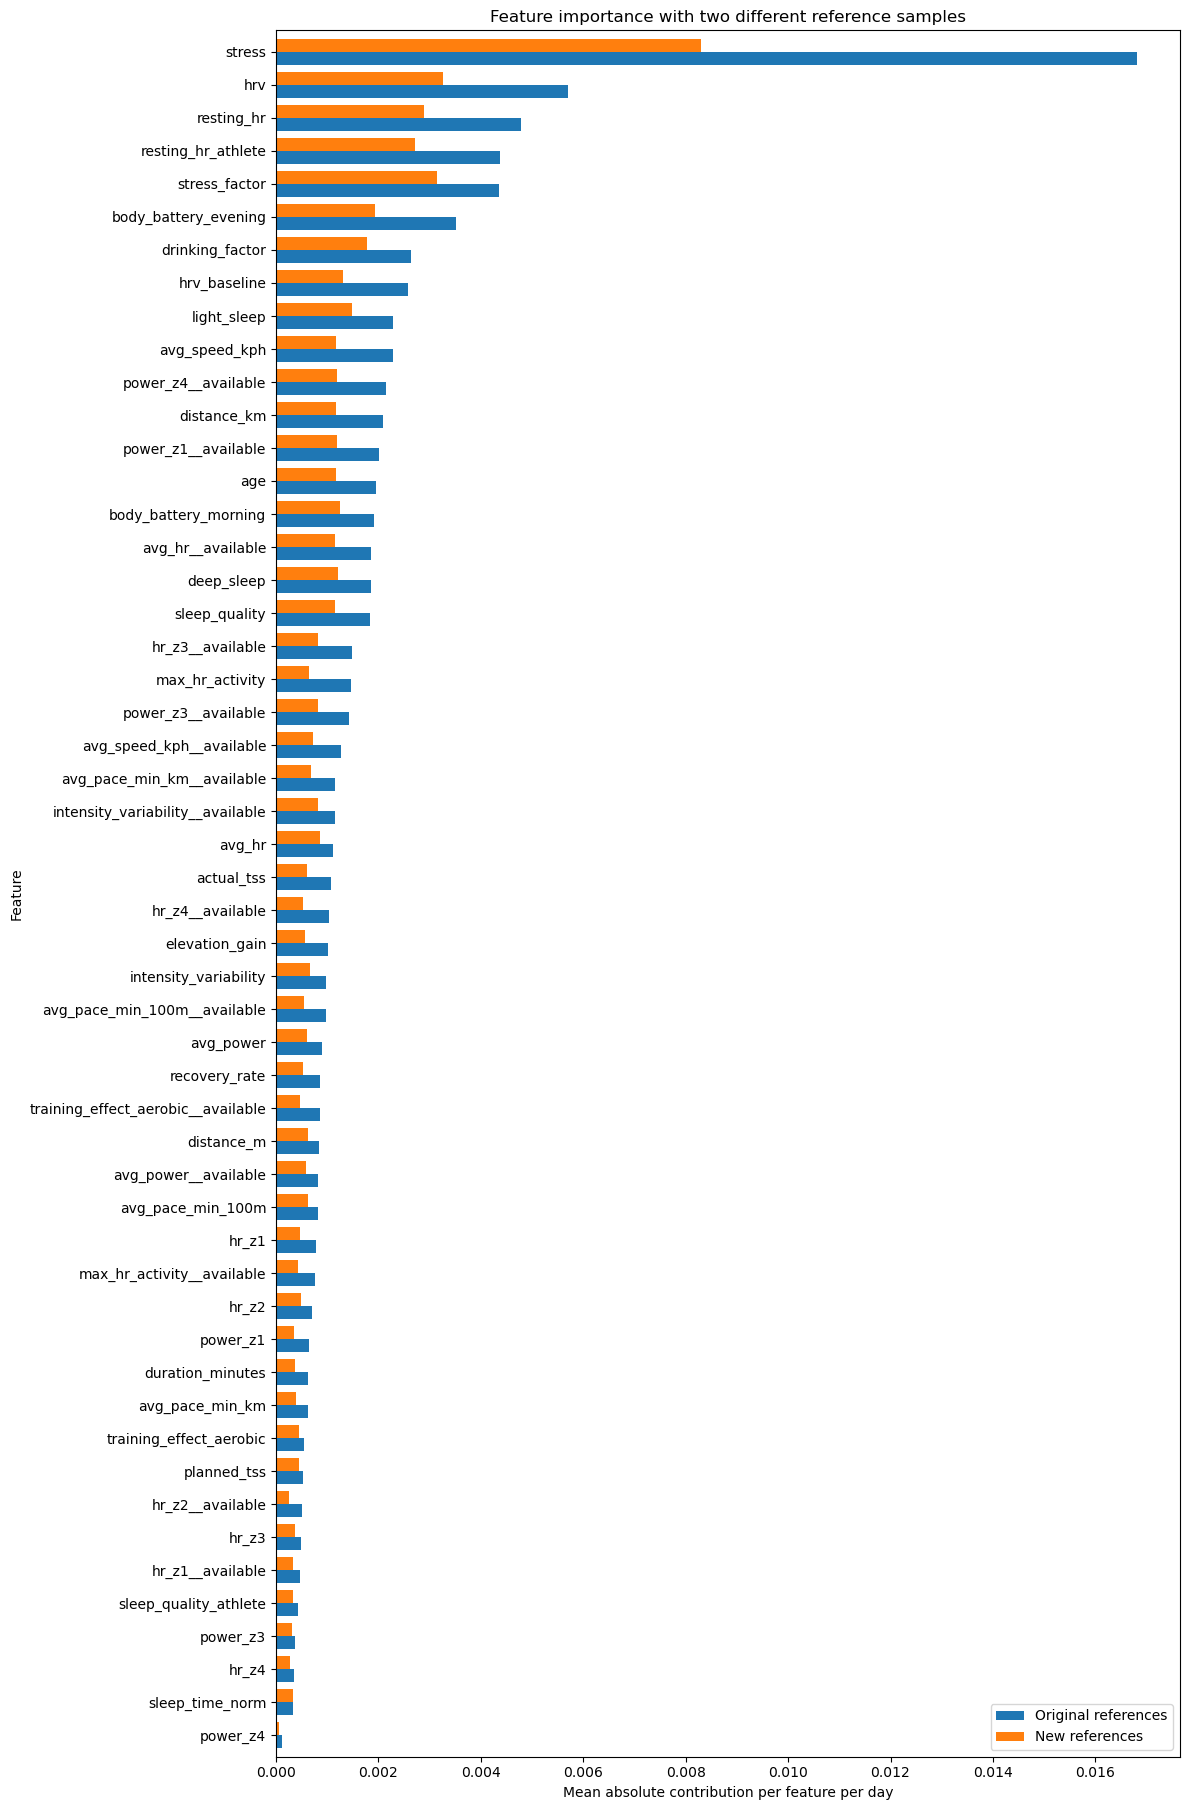

In [79]:
#Compare feature rankings across the two reference samples

if not stability_passed:
    raise ValueError(
        "The new numerical check failed. Rerun Step 10 with "
        "steps=128, then run this cell again.")

original_importance = np.abs(
    feature_contributions).mean(axis=(0, 1))

new_importance = np.abs(
    stability_contributions).mean(axis=(0, 1))

stability_comparison = pd.DataFrame({"Feature": explain_feature_names,"Original_importance": original_importance,"New_importance": new_importance})
stability_comparison["Original_rank"] = (stability_comparison["Original_importance"].rank(ascending=False, method="average"))
stability_comparison["New_rank"] = (stability_comparison["New_importance"].rank(ascending=False, method="average"))
stability_comparison["Rank_change"] = (stability_comparison["New_rank"]- stability_comparison["Original_rank"])

# Correlation of ranks is Spearman rank correlation.
rank_correlation = stability_comparison["Original_rank"].corr(stability_comparison["New_rank"])

original_top5 = set(
    stability_comparison.nlargest(5, "Original_importance")["Feature"])

new_top5 = set(
    stability_comparison.nlargest(5, "New_importance")["Feature"])

stability_comparison = stability_comparison.sort_values("Original_rank").reset_index(drop=True)
display(stability_comparison.round(6))

print(f"\nRank correlation: {rank_correlation:.3f}")
print(
    f"Shared top-five features: "
    f"{len(original_top5 & new_top5)}/5")

# Plot
plot_data = stability_comparison.set_index("Feature")[["Original_importance", "New_importance"]].iloc[::-1]

ax = plot_data.plot.barh(figsize=(12, max(8, len(plot_data) * 0.35)),width=0.8)

ax.set_xlabel("Mean absolute contribution per feature per day")
ax.set_ylabel("Feature")
ax.set_title("Feature importance with two different reference samples")
ax.legend(["Original references", "New references"])

fig = ax.get_figure()
fig.tight_layout()
plt.show()
plt.close(fig)

## Explainable Machine Learning - 512 sample

In [80]:
larger_rng = np.random.default_rng(2026)
target_size = min(512, len(X_val))

# Select additional windows without repeating the original ones.
remaining_indices = np.setdiff1d(
    np.arange(len(X_val)),
    explain_indices)

additional_count = target_size - len(explain_indices)
additional_indices = larger_rng.choice(remaining_indices,size=additional_count,replace=False)

# Keep the original windows first, followed by the new windows.
larger_explain_indices = np.concatenate([explain_indices,additional_indices])
larger_explain_windows = X_val[larger_explain_indices]

print("Original windows:", len(explain_indices))
print("Additional windows:", len(additional_indices))
print("Total windows:", len(larger_explain_indices))
print("Larger sample shape:", larger_explain_windows.shape)
print("References remain unchanged:", reference_windows.shape)

Original windows: 128
Additional windows: 384
Total windows: 512
Larger sample shape: (512, 14, 52)
References remain unchanged: (8, 14, 52)


In [81]:
# additional windows and check accuracy

additional_windows = X_val[additional_indices]
additional_contributions = np.zeros_like(additional_windows,dtype=np.float32)

if len(additional_windows) > 0:
    for number, reference in enumerate(reference_windows, start=1):
        print(
            f"Processing reference {number}/{len(reference_windows)} "
            f"for {len(additional_windows)} additional windows",flush=True)

        additional_contributions += integrated_gradients(explain_model,additional_windows,reference,steps=64) / len(reference_windows)

# original windows first, then additional windows.
larger_contributions = np.concatenate([feature_contributions,additional_contributions], axis=0)
larger_probabilities = explain_model.predict(larger_explain_windows,batch_size=256,verbose=0).ravel()
larger_reconstructed = (reference_mean_probability + larger_contributions.sum(axis=(1, 2)))
larger_errors = np.abs(larger_probabilities - larger_reconstructed)
larger_passed = bool(np.isfinite(larger_contributions).all()
    and np.isfinite(larger_errors).all()
    and larger_errors.max() <= 0.005)

print("\nContribution shape:", larger_contributions.shape)
print(f"Mean absolute error: {larger_errors.mean():.6f}")
print(f"Maximum absolute error: {larger_errors.max():.6f}")
print("Numerical check passed:", larger_passed)

Processing reference 1/8 for 384 additional windows
Processing reference 2/8 for 384 additional windows
Processing reference 3/8 for 384 additional windows
Processing reference 4/8 for 384 additional windows
Processing reference 5/8 for 384 additional windows
Processing reference 6/8 for 384 additional windows
Processing reference 7/8 for 384 additional windows
Processing reference 8/8 for 384 additional windows

Contribution shape: (512, 14, 52)
Mean absolute error: 0.000008
Maximum absolute error: 0.000093
Numerical check passed: True


,Feature,Original_importance,Larger_importance,Original_rank,Larger_rank
0,stress,0.016812,0.015857,1.0,1.0
1,hrv,0.005692,0.004887,2.0,3.0
2,resting_hr,0.004779,0.004990,3.0,2.0
3,resting_hr_athlete,0.004374,0.004592,4.0,4.0
4,stress_factor,0.004361,0.004360,5.0,5.0
5,body_battery_evening,0.003523,0.003492,6.0,6.0
6,drinking_factor,0.002641,0.002429,7.0,7.0
7,hrv_baseline,0.002577,0.002163,8.0,10.0
8,light_sleep,0.002290,0.002373,9.0,8.0
9,avg_speed_kph,0.002287,0.002163,10.0,9.0


Rank correlation: 0.996
Shared top-five features: 5/5


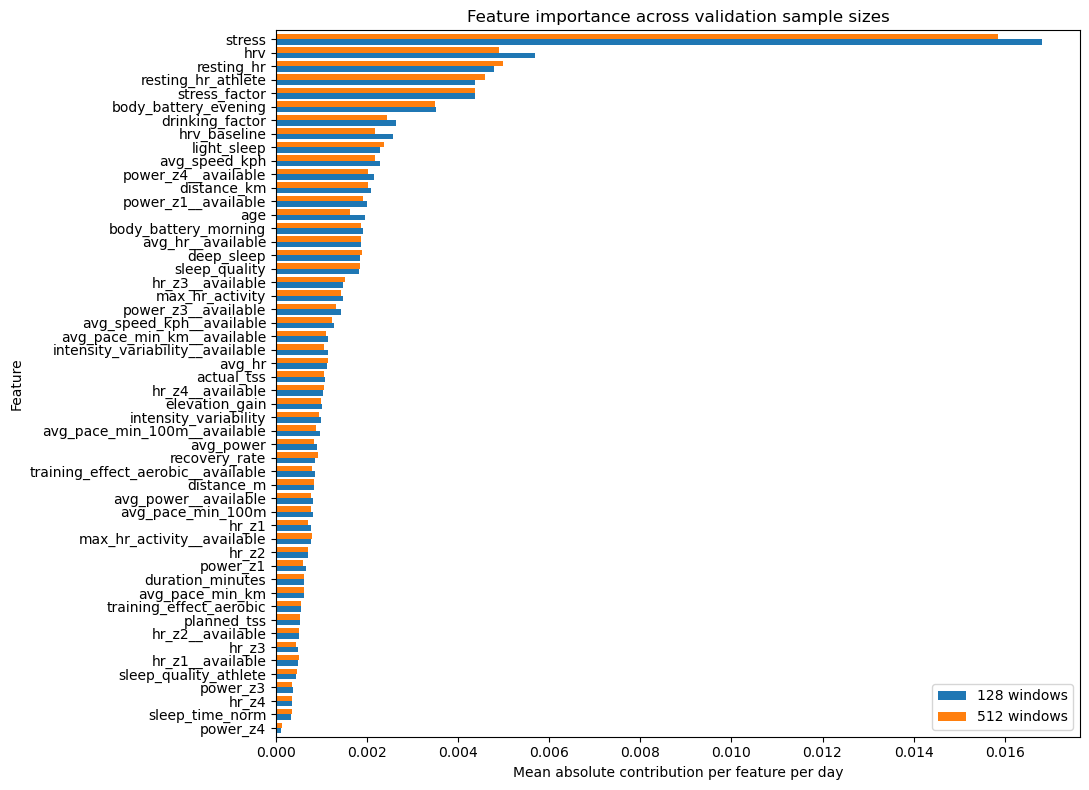

In [82]:
# Compare importance (128 vs 512)

if not larger_passed:
    raise ValueError("The larger-sample numerical check must pass first.")

sample_comparison = pd.DataFrame({"Feature": explain_feature_names,"Original_importance": np.abs(
        feature_contributions).mean(axis=(0, 1)),
    "Larger_importance": np.abs(larger_contributions).mean(axis=(0, 1))})

sample_comparison["Original_rank"] = (sample_comparison["Original_importance"]
    .rank(ascending=False, method="average"))
sample_comparison["Larger_rank"] = (sample_comparison["Larger_importance"]
    .rank(ascending=False, method="average"))
sample_rank_correlation = sample_comparison["Original_rank"].corr(sample_comparison["Larger_rank"])
original_top5 = set(sample_comparison.nlargest(5, "Original_importance")["Feature"])
larger_top5 = set(sample_comparison.nlargest(5, "Larger_importance")["Feature"])
sample_comparison = sample_comparison.sort_values("Original_rank").reset_index(drop=True)
display(sample_comparison.round(6))
print(f"Rank correlation: {sample_rank_correlation:.3f}")
print(f"Shared top-five features: {len(original_top5 & larger_top5)}/5")

plot_data = sample_comparison.set_index("Feature")[["Original_importance", "Larger_importance"]].iloc[::-1]

ax = plot_data.plot.barh(figsize=(11, 8), width=0.8)
ax.set_xlabel("Mean absolute contribution per feature per day")
ax.set_ylabel("Feature")
ax.set_title("Feature importance across validation sample sizes")
ax.legend([
    f"{len(explain_indices)} windows",
    f"{len(larger_explain_indices)} windows"])
plt.tight_layout()
plt.show()

## Training Settings

In [83]:
# Methodology: Section D
dates = pd.to_datetime(df["date"], errors="coerce")
records_per_athlete = df.groupby("athlete_id").size()
invalid_injury = (df["injury"].notna()& ~df["injury"].isin([0, 1]))

table_4 = pd.DataFrame({"Check": [
        "Daily records","Athletes","Records per athlete (minimum–maximum)","Missing athlete identifiers","Missing or invalid dates",
        "Duplicate athlete and date combinations","Missing injury values","Injury values other than 0 or 1","Records marked as uninjured",
        "Records marked as injured"],
    "Result": [f"{len(df):,}",f"{df['athlete_id'].nunique():,}",f"{records_per_athlete.min():,}–{records_per_athlete.max():,}",
        f"{df['athlete_id'].isna().sum():,}",f"{dates.isna().sum():,}",f"{df.duplicated(['athlete_id', 'date']).sum():,}",
        f"{df['injury'].isna().sum():,}",f"{invalid_injury.sum():,}",f"{df['injury'].eq(0).sum():,}",
        f"{df['injury'].eq(1).sum():,}"]
})
display(table_4)

,Check,Result
0,Daily records,"366,000"
1,Athletes,"1,000"
2,Records per athlete (minimum–maximum),366–366
3,Missing athlete identifiers,0
4,Missing or invalid dates,0
5,Duplicate athlete and date combinations,0
6,Missing injury values,0
7,Injury values other than 0 or 1,0
8,Records marked as uninjured,"336,198"
9,Records marked as injured,"29,802"


In [84]:
# Methodology: Section H
training_settings = pd.DataFrame({"Setting": [
        "Input sequence","Optimiser","Learning rate","Loss function","Batch size","Maximum epochs","Dropout rate","Early-stopping measure",
        "Early-stopping patience","Output","Random seed"],
    "Value": [f"{HISTORY_DAYS} days with {X_train.shape[2]} inputs per day",
        "Adam","0.001","Binary cross-entropy","256","20","0.20","Validation PR-AUC","3 epochs","One sigmoid node","42"]})
display(training_settings.style.hide(axis="index"))

Setting,Value
Input sequence,14 days with 52 inputs per day
Optimiser,Adam
Learning rate,0.001
Loss function,Binary cross-entropy
Batch size,256
Maximum epochs,20
Dropout rate,0.20
Early-stopping measure,Validation PR-AUC
Early-stopping patience,3 epochs
Output,One sigmoid node


In [85]:
# Section I
threshold_table = pd.DataFrame({"Model": [f"LSTM with {best_units} hidden units","CNN","Simple RNN"],
    "Selected threshold": [best_lstm_threshold,cnn_selected_threshold,rnn_selected_threshold]})
display(threshold_table.style.hide(axis="index").format({"Selected threshold": "{:.4f}"}))

Model,Selected threshold
LSTM with 16 hidden units,0.3313
CNN,0.3081
Simple RNN,0.4015


In [86]:
selected_lstm_threshold_comparison = (
    lstm_threshold_comparison.loc[lstm_threshold_comparison["Hidden_units"].eq(best_units),[
            "Setting", "Threshold", "Precision", "Recall","F1", "False_positives", "False_negatives"]
    ])

display(selected_lstm_threshold_comparison.style
    .hide(axis="index")
    .format({"Threshold": "{:.4f}","Precision": "{:.4f}","Recall": "{:.4f}","F1": "{:.4f}"}))

Setting,Threshold,Precision,Recall,F1,False_positives,False_negatives
Default,0.5000,0.9186,0.6118,0.7344,245,1754
Selected using validation F1,0.3313,0.8772,0.6436,0.7425,407,1610
